# Data Professionals Salary Analysis

## Análise estatística dos salários de profissionais de dados

Este projeto tem como objetivo realizar uma análise estatística dos salários de profissionais da área de dados, buscando compreender como fatores profissionais, geográficos e organizacionais estão associados à remuneração.

A análise utiliza a base `salario_profissionais_dados.csv`, contendo informações sobre cargos, nível de experiência, regime de trabalho, localização, tamanho das empresas e salários.

O projeto será desenvolvido seguindo um fluxo estruturado de análise de dados, incluindo:

- compreensão e inspeção da base;
- avaliação da qualidade dos dados;
- análise de registros duplicados;
- estatística descritiva;
- análise da distribuição salarial;
- comparação salarial por nível de experiência;
- comparação entre cargos;
- análise por localização;
- análise por tamanho da empresa;
- avaliação do trabalho remoto;
- estudo das relações entre variáveis;
- identificação de valores extremos;
- principais insights;
- conclusão e limitações da análise.


## 1. Configuração do ambiente

Nesta etapa são importadas as bibliotecas necessárias para manipulação, análise estatística e visualização dos dados.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import FuncFormatter

import warnings

warnings.filterwarnings("ignore")

In [2]:
pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

## 2. Carregamento dos dados

A base será carregada a partir da pasta `data/`, mantendo a organização do projeto e permitindo sua reprodução em outros ambientes.


In [3]:
df = pd.read_csv("../data/salario_profissionais_dados.csv")

print(f"Quantidade de registros: {df.shape[0]:,}")
print(f"Quantidade de colunas: {df.shape[1]}")

Quantidade de registros: 3,755
Quantidade de colunas: 10


### 2.1 Dimensões e estrutura da base

Antes de iniciar as análises estatísticas, é importante verificar a estrutura dos dados, os tipos das variáveis e a quantidade de informações disponíveis.


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3755 entries, 0 to 3754
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   work_year            3755 non-null   int64 
 1   country              3755 non-null   object
 2   region               3755 non-null   object
 3   experience_level     3755 non-null   object
 4   job_title            3755 non-null   object
 5   salary_in_usd        3755 non-null   int64 
 6   employee_residence   3755 non-null   object
 7   company_location     3755 non-null   object
 8   company_size         3755 non-null   object
 9   years_of_experience  3755 non-null   int64 
dtypes: int64(3), object(7)
memory usage: 293.5+ KB


In [5]:
df.columns.tolist()

['work_year',
 'country',
 'region',
 'experience_level',
 'job_title',
 'salary_in_usd',
 'employee_residence',
 'company_location',
 'company_size',
 'years_of_experience']

In [6]:
df.head()

,work_year,country,region,experience_level,job_title,salary_in_usd,employee_residence,company_location,company_size,years_of_experience
0,2023,Spain,Europe,SE,Principal Data Scientist,85847,ES,ES,L,8
1,2023,United States of America,Americas,MI,ML Engineer,30000,US,US,S,5
2,2023,United States of America,Americas,MI,ML Engineer,25500,US,US,S,3
3,2023,Canada,Americas,SE,Data Scientist,175000,CA,CA,M,8
4,2023,Canada,Americas,SE,Data Scientist,120000,CA,CA,M,8


## 3. Entendimento e qualidade dos dados

Antes das análises estatísticas, será realizada uma realização da estrutura e da qualidade da base.

- significado das variáveis;
- valores ausentes;
- registros duplicados;
- quantidade de categorias;
- consistência geral dos dados.


### 3.1 Dicionário das variáveis

A base contém informações profissionais, geográficas e salariais relacionadas a profissionais da área de dados.

As variáveis disponíveis são:

| Variável              | Descrição                                        |
| --------------------- | ------------------------------------------------ |
| `work_year`           | Ano de referência do registro salarial           |
| `country`             | País associado ao profissional                   |
| `region`              | Região geográfica do país                        |
| `experience_level`    | Nível de experiência profissional                |
| `job_title`           | Cargo exercido pelo profissional                 |
| `salary_in_usd`       | Salário anual convertido para dólares americanos |
| `employee_residence`  | País de residência do profissional               |
| `company_location`    | País onde a empresa está localizada              |
| `company_size`        | Porte da empresa                                 |
| `years_of_experience` | Quantidade de anos de experiência profissional   |


### 3.2 Valores ausentes

A presença de valores ausentes pode comprometer análises estatísticas e comparações entre grupos. Por isso, será verificada a quantidade e o percentual de valores ausentes em cada variável.


In [7]:
missing_data = pd.DataFrame(
    {
        "Valores ausentes": df.isnull().sum(),
        "Percentual": (df.isnull().mean() * 100).round(2),
    }
)

missing_data

,Valores ausentes,Percentual
work_year,0,0.0
country,0,0.0
region,0,0.0
experience_level,0,0.0
job_title,0,0.0
salary_in_usd,0,0.0
employee_residence,0,0.0
company_location,0,0.0
company_size,0,0.0
years_of_experience,0,0.0


**Interpretação:**

Não foram identificados valores ausentes nas variáveis da base.

Portanto, não será necessário realizar imputação ou exclusão de registros por ausência de informações.


### 3.3 Análise de registros duplicados

Registros duplicados serão investigados antes de qualquer remoção.

Em bases salariais, linhas completamente iguais não representam necessariamente erros, pois diferentes profissionais podem possuir exatamente as mesmas características, como cargo, salário, experiência e localização.

Por esse motivo, a identificação de duplicatas será inicialmente tratada como uma etapa de investigação, e não como motivo automático para exclusão.


In [8]:
duplicates = df.duplicated().sum()

percen_duplicates = duplicates / len(df) * 100

print(f"Registros duplicados: " f"{duplicates:,}")

print(f"Percentual da base: " f"{percen_duplicates:.2f}%")

Registros duplicados: 786
Percentual da base: 20.93%


In [9]:
df[df.duplicated(keep=False)].sort_values(by=list(df.columns)).head(20)

,work_year,country,region,experience_level,job_title,salary_in_usd,employee_residence,company_location,company_size,years_of_experience
3464,2021,United States of America,Americas,SE,Data Engineer,150000,US,US,L,7
3575,2021,United States of America,Americas,SE,Data Engineer,150000,US,US,L,7
2888,2022,Greece,Europe,MI,Data Engineer,84053,GR,GR,M,4
3204,2022,Greece,Europe,MI,Data Engineer,84053,GR,GR,M,4
2677,2022,Spain,Europe,SE,Data Analyst,36773,ES,ES,M,6
2783,2022,Spain,Europe,SE,Data Analyst,36773,ES,ES,M,6
2013,2022,Spain,Europe,SE,Data Analyst,50432,ES,ES,M,8
2538,2022,Spain,Europe,SE,Data Analyst,50432,ES,ES,M,8
2782,2022,Spain,Europe,SE,Data Analyst,50432,ES,ES,M,8
1941,2022,Spain,Europe,SE,Data Engineer,36773,ES,ES,M,8


### 3.4 Frequência dos registros repetidos

Para compreender melhor as duplicadas, será analisada a frequência com que combinações completamente idênticas aparecem na base.


In [10]:
freq_registros = (
    df.value_counts()
    .reset_index(name="Frequencia")
    .sort_values("Frequencia", ascending=False)
)

freq_registros.head(10)

,work_year,country,region,experience_level,job_title,salary_in_usd,employee_residence,company_location,company_size,years_of_experience,Frequencia
0,2022,United States of America,Americas,SE,Data Scientist,141525,US,US,M,6,11
1,2023,United States of America,Americas,SE,Data Engineer,160000,US,US,M,6,10
2,2022,United States of America,Americas,SE,Data Scientist,141525,US,US,M,7,9
6,2022,United States of America,Americas,SE,Data Scientist,191475,US,US,M,8,8
5,2023,United States of America,Americas,SE,Data Engineer,129000,US,US,M,6,8
3,2022,United States of America,Americas,SE,Data Engineer,130000,US,US,M,7,8
4,2022,United States of America,Americas,SE,Data Scientist,191475,US,US,M,7,8
7,2022,United States of America,Americas,SE,Data Scientist,140000,US,US,M,8,7
11,2023,United States of America,Americas,SE,Machine Learning Engineer,150000,US,US,M,7,6
9,2023,United States of America,Americas,SE,Data Engineer,252000,US,US,M,6,6


### 3.5 Quantidade de valores únicos

A quantidade de valores distintos em cada variável ajuda a compreender a cardinalidade da base e identificar quais atributos possuem maior diversidade de categorias.


In [11]:
valores_unicos = (
    df.nunique().sort_values(ascending=False).to_frame(name="Valores_Unicos")
)

valores_unicos

,Valores_Unicos
salary_in_usd,1035
job_title,93
employee_residence,78
country,78
company_location,72
years_of_experience,10
region,5
work_year,4
experience_level,4
company_size,3


In [12]:
for coluna in ["experience_level", "company_size", "region"]:
    print(f"\n{coluna}:")
    print(df[coluna].value_counts())


experience_level:
experience_level
SE    2516
MI     805
EN     320
EX     114
Name: count, dtype: int64

company_size:
company_size
M    3153
L     454
S     148
Name: count, dtype: int64

region:
region
Americas    3140
Europe       464
Asia         120
Africa        17
Oceania       14
Name: count, dtype: int64


In [13]:
df["work_year"].value_counts().sort_index()

work_year
2020      76
2021     230
2022    1664
2023    1785
Name: count, dtype: int64

### 3.6 Interpretação da estrutura da base

A análise das categorias mostra que o conjunto de dados apresenta concentração relevante em alguns grupos.

Em relação ao nível de experiência:

- `SE` (Senior) possui 2.516 registros, representando aproximadamente 67% da base;
- `MI` (Mid-level) possui 805 registros;
- `EN` (Entry-level) possui 320 registros;
- `EX` (Executive) possui 114 registros.

Quanto ao porte das empresas, observa-se forte predominância de empresas médias (`M`), com 3.153 registros, enquanto empresas grandes (`L`) possuem 454 registros e empresas pequenas (`S`) apenas 148.

A distribuição geográfica também é bastante concentrada:

- Americas: 3.140 registros;
- Europe: 464 registros;
- Asia: 120 registros;
- Africa: 17 registros;
- Oceania: 14 registros.

Em relação ao período analisado, a maior parte das observações pertence aos anos mais recentes:

- 2020: 76 registros;
- 2021: 230 registros;
- 2022: 1.664 registros;
- 2023: 1.785 registros.

Essa desigualdade na quantidade de observações entre categorias deverá ser considerada nas comparações futuras, principalmente para grupos com poucas observações.

A base também possui elevada diversidade profissional, contendo 93 cargos diferentes e 1.035 valores distintos de salário.


### 3.7 Decisão sobre registros duplicados

Foram identificadas combinações de registros completamente iguais na base, algumas ocorrendo diversas vezes.

Entretanto, o conjunto de dados não possui um identificador único para cada profissional.

Consequentemente, não é possível determinar se duas linhas iguais representam:

1. um registro duplicado do mesmo profissional; ou
2. profissionais distintos que compartilham exatamente as mesmas características.

A remoção automática dessas observações poderia eliminar registros legítimos e alterar artificialmente a distribuição dos dados.

Por esse motivo, os registros serão **mantidos na análise principal**.

Essa decisão será considerada como uma limitação do conjunto de dados e mencionada na conclusão do projeto.


## 4. Estatística descritiva dos salários

Nesta etapa será analisada a distribuição da variável `salary_in_usd`, com foco em medidas de tendência central, dispersão e posição.

O objetivo é compreender o comportamento geral dos salários antes de realizar comparações entre cargos, níveis de experiência, regiões e outros grupos.


### 4.1 Medidas de tendência central e dispersão

Serão calculadas medidas estatísticas que ajudam a resumir a distribuição salarial, incluindo média, mediana, mínimo, máximo, quartis e desvio padrão.


In [14]:
estatist_salario = df["salary_in_usd"].describe()

estatist_salario

count      3755.000000
mean     137570.389880
std       63055.625278
min        5132.000000
25%       95000.000000
50%      135000.000000
75%      175000.000000
max      450000.000000
Name: salary_in_usd, dtype: float64

In [15]:
resumo_salario = pd.DataFrame(
    {
        "Indicador": [
            "Quantidade",
            "Média",
            "Mediana",
            "Desvio Padrão",
            "Mínimo",
            "1º Quartil",
            "2º Quartil",
            "Máximo",
        ],
        "Valor": [
            df["salary_in_usd"].count(),
            df["salary_in_usd"].mean(),
            df["salary_in_usd"].median(),
            df["salary_in_usd"].std(),
            df["salary_in_usd"].min(),
            df["salary_in_usd"].quantile(0.25),
            df["salary_in_usd"].quantile(0.75),
            df["salary_in_usd"].max(),
        ],
    }
)

resumo_salario_display = resumo_salario.copy()

resumo_salario_display.loc[
    resumo_salario_display["Indicador"] == "Quantidade", "Valor"
] = f"{int(df['salary_in_usd'].count()):,}"

for indicador in [
    "Média",
    "Mediana",
    "Desvio padrão",
    "Mínimo",
    "1º quartil",
    "3º quartil",
    "Máximo",
]:
    resumo_salario_display.loc[
        resumo_salario_display["Indicador"] == indicador, "Valor"
    ] = resumo_salario.loc[resumo_salario["Indicador"] == indicador, "Valor"].map(
        lambda x: f"US$ {x:,.2f}"
    )

resumo_salario_display

,Indicador,Valor
0,Quantidade,"3,755"
1,Média,"US$ 137,570.39"
2,Mediana,"US$ 135,000.00"
3,Desvio Padrão,63055.625278
4,Mínimo,"US$ 5,132.00"
5,1º Quartil,95000.0
6,2º Quartil,175000.0
7,Máximo,"US$ 450,000.00"


### 4.2 Amplitude salarial

A amplitude representa a diferença entre o maior e o menor salário observado na base e ajuda a compreender o intervalo total de remunerações.


In [16]:
amplitude_salario = df["salary_in_usd"].max() - df["salary_in_usd"].min()

print(f"Amplitude salarial: " f"US$ {amplitude_salario:,.2f}")

Amplitude salarial: US$ 444,868.00


### 4.3 Intervalo interquartil

O intervalo interquartil (IQR) representa a dispersão dos 50% centrais dos salários e será utilizado posteriormente para investigar possíveis valores extremos.


In [17]:
q1_salario = df["salary_in_usd"].quantile(0.25)
q3_salario = df["salary_in_usd"].quantile(0.75)

iqr_salario = q3_salario - q1_salario

print(f"Q1: US$ {q1_salario:,.2f}")
print(f"Q3: US$ {q3_salario:,.2f}")
print(f"IQR: US$ {iqr_salario:,.2f}")

Q1: US$ 95,000.00
Q3: US$ 175,000.00
IQR: US$ 80,000.00


### 4.4 Coeficiente de variação

O coeficiente de variação relaciona o desvio padrão à média e permite avaliar a dispersão relativa dos salários.


In [18]:
coef_variacao = df["salary_in_usd"].std() / df["salary_in_usd"].mean() * 100

print(f"Coeficiente de variação: " f"{coef_variacao:,.2f}")

Coeficiente de variação: 45.84


### 4.5 Assimetria da distribuição salarial

A assimetria ajuda a identificar se a distribuição dos salários é aproximadamente equilibrada ou se existe maior concentração de valores em uma das extremidades.


In [19]:
assimetria_salario = df["salary_in_usd"].skew()

print(f"Assimetria: " f"{assimetria_salario:.4f}")

Assimetria: 0.5364


### 4.6 Distribuição dos salários

A distribuição será visualizada por meio de um histograma com curva de densidade, permitindo observar concentração, dispersão e possíveis assimetrias nos salários.


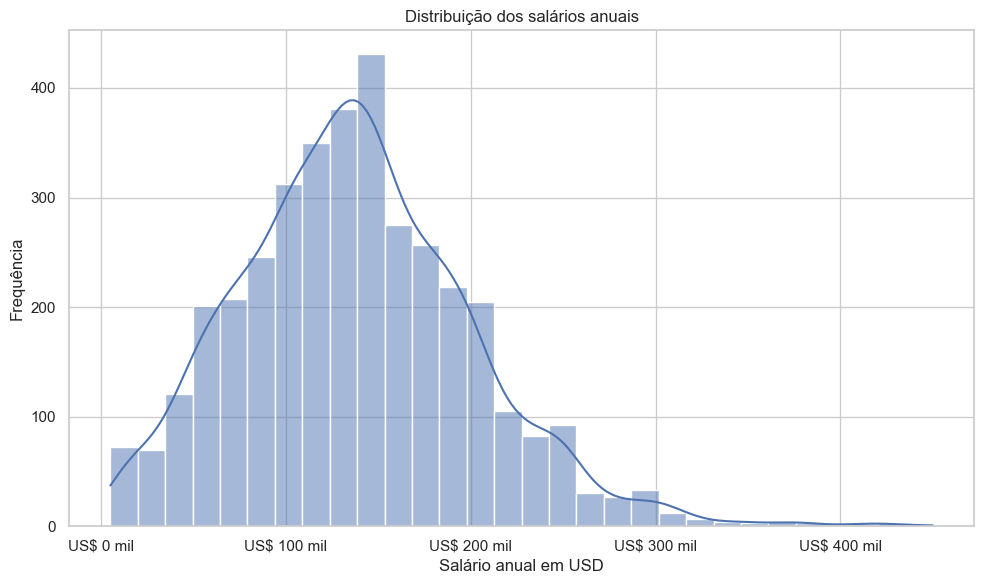

In [20]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="salary_in_usd", bins=30, kde=True)

plt.title("Distribuição dos salários anuais")
plt.xlabel("Salário anual em USD")
plt.ylabel("Frequência")

ax = plt.gca()

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"US$ {x / 1_000:.0f} mil"))

plt.tight_layout()

plt.savefig("../images/distribuição_salarios.png", dpi=300, bbox_inches="tight")

plt.show()

### 4.7 Boxplot da distribuição salarial

O boxplot permite visualizar a mediana, os quartis, a dispersão dos salários e possíveis observações extremas.


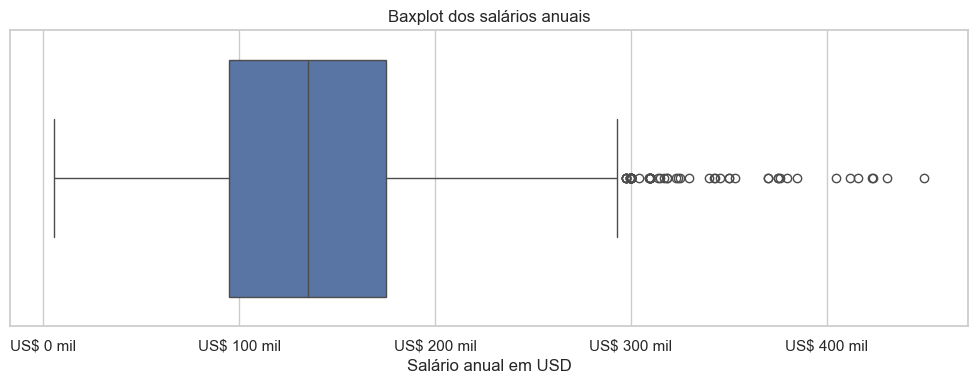

In [21]:
plt.figure(figsize=(10, 4))

sns.boxplot(data=df, x="salary_in_usd")

plt.title("Baxplot dos salários anuais")
plt.xlabel("Salário anual em USD")

ax = plt.gca()

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"US$ {x / 1_000:.0f} mil"))

plt.tight_layout()
plt.show()

### 4.8 Interpretação da distribuição salarial

A análise descritiva da variável `salary_in_usd` mostrou que a base contém **3.755 registros**, com **salário médio de US$ 137.570,39** e **mediana de US$ 135.000,00**. Como média e mediana estão relativamente próximas, observa-se uma distribuição com centro bem definido, embora exista uma leve influência de salários mais altos.

A dispersão dos salários é relevante. O **desvio padrão de US$ 63.055,63** e o **coeficiente de variação de 45,84%** indicam variabilidade considerável nas remunerações, o que é coerente com um mercado de dados composto por diferentes cargos, níveis de experiência, regiões e portes de empresa.

A análise dos quartis mostrou que **25% dos salários estão abaixo de US$ 95.000,00**, enquanto **75% estão abaixo de US$ 175.000,00**, resultando em um **intervalo interquartil de US$ 80.000,00**. Isso significa que os 50% centrais da distribuição se concentram nesse intervalo, sugerindo uma faixa salarial relativamente ampla mesmo entre os valores centrais.

A **amplitude salarial de US$ 444.868,00**, com mínimo de **US$ 5.132,00** e máximo de **US$ 450.000,00**, evidencia grande diferença entre os menores e os maiores salários observados na base.

A **assimetria positiva de 0,5364** indica que a distribuição possui **cauda à direita**, ou seja, há salários elevados puxando a distribuição para cima. Esse comportamento também aparece no histograma, em que a maior concentração está aproximadamente entre **US$ 100 mil e US$ 180 mil**, com redução gradual da frequência nos salários mais altos.

O boxplot reforça essa leitura ao evidenciar a presença de **diversos valores extremos superiores**, principalmente acima da faixa próxima de **US$ 295 mil**, o que sugere a existência de profissionais ou posições com remunerações substancialmente acima da maior parte da amostra.

De forma geral, a variável `salary_in_usd` apresenta distribuição **moderadamente assimétrica à direita**, **alta dispersão** e **presença de outliers superiores**, características esperadas em dados salariais de um mercado com forte heterogeneidade entre funções e níveis profissionais.


## 5. Investigação de outliers salariais

A distribuição de `salary_in_usd` apresentou valores elevados em relação à maior parte da base.

Nesta etapa, será utilizado o método do intervalo interquartil (IQR) para identificar possíveis outliers salariais.

A identificação de um valor como outlier estatístico não significa, necessariamente, que ele represente um erro. Em dados salariais, remunerações muito altas podem estar associadas a cargos executivos, níveis elevados de experiência, empresas específicas ou mercados com maior remuneração.

Por esse motivo, os valores extremos serão investigados antes de qualquer decisão de remoção.


### 5.1 Definição dos limites

Os limites inferior e superior serão calculados utilizando 1,5 vezes o intervalo interquartil.


In [22]:
lower_salary_limit = q1_salario - 1.5 * iqr_salario
upper_salary_limit = q3_salario + 1.5 * iqr_salario

print(f"Limite inferior:" f"U$ {lower_salary_limit:,.2f}")
print(f"Limite superior:" f"US {upper_salary_limit:,.2f}")

Limite inferior:U$ -25,000.00
Limite superior:US 295,000.00


### 5.2 Quantidade de outliers

Serão considerados possíveis outliers os salários abaixo do limite inferior ou acima do limite superior definido pelo método do IQR.


In [23]:
outliers_salary = df[
    (df["salary_in_usd"] < lower_salary_limit)
    | (df["salary_in_usd"] > upper_salary_limit)
]

quantity_outliers = len(outliers_salary)

percentage_outliers = quantity_outliers / len(df) * 100

print(f"Quantidade de possíveis outliers: " f"{quantity_outliers:,}")
print(f"Percentual da base: " f"{percentage_outliers:.2f}%")

Quantidade de possíveis outliers: 63
Percentual da base: 1.68%


### 5.3 Resultado da identificação de outliers

Utilizando o método do intervalo interquartil, foram identificados **63 possíveis outliers salariais**, correspondentes a aproximadamente **1,68% da base**.

O limite inferior calculado foi de **-US$ 25.000,00**, enquanto o valor superior foi de **US$ 295.000,00**.

Como salários negativos não estão presentes na base, os valores classificados como extremos estão concentrados exclusivamente na parte superior da distribuição.

A proporção reduzida de observações extremas indica que esses registros representam uma pequena parcela do conjunto de dados. Entretanto, antes de qualquer remoção, será analisado o perfil profissional associado a esses salários.


### 5.4 Inspeção dos maiores salários

Os registros classificados como outliers serão analisados para verificar se possuem características plausíveis dentro do contexto profissional da base.


In [24]:
outliers_salary[
    [
        "work_year",
        "country",
        "experience_level",
        "job_title",
        "salary_in_usd",
        "company_location",
        "company_size",
        "years_of_experience",
    ]
].sort_values("salary_in_usd", ascending=False).head(20)

,work_year,country,experience_level,job_title,salary_in_usd,company_location,company_size,years_of_experience
3522,2020,United States of America,MI,Research Scientist,450000,US,M,4
2011,2022,United Kingdom of Great Britain and Northern I...,MI,Data Analyst,430967,GB,M,5
528,2023,Israel,SE,AI Scientist,423834,IL,L,6
3747,2021,United States of America,MI,Applied Machine Learning Scientist,423000,US,L,3
3675,2021,United States of America,EX,Principal Data Scientist,416000,US,S,9
3750,2020,United States of America,SE,Data Scientist,412000,US,L,6
3463,2022,United States of America,SE,Data Analytics Lead,405000,US,L,8
1288,2023,United States of America,SE,Data Analyst,385000,US,M,7
3468,2022,United States of America,SE,Applied Data Scientist,380000,US,L,8
649,2023,United States of America,SE,Data Architect,376080,US,M,8


In [25]:
outliers_salary_display = (
    outliers_salary[
        [
            "work_year",
            "country",
            "experience_level",
            "job_title",
            "salary_in_usd",
            "company_location",
            "company_size",
            "years_of_experience",
        ]
    ]
    .sort_values("salary_in_usd", ascending=False)
    .head(20)
    .copy()
)

outliers_salary_display["salary_in_usd"] = outliers_salary_display["salary_in_usd"].map(
    lambda x: f"US$ {x:,.2f}"
)

outliers_salary_display

,work_year,country,experience_level,job_title,salary_in_usd,company_location,company_size,years_of_experience
3522,2020,United States of America,MI,Research Scientist,"US$ 450,000.00",US,M,4
2011,2022,United Kingdom of Great Britain and Northern I...,MI,Data Analyst,"US$ 430,967.00",GB,M,5
528,2023,Israel,SE,AI Scientist,"US$ 423,834.00",IL,L,6
3747,2021,United States of America,MI,Applied Machine Learning Scientist,"US$ 423,000.00",US,L,3
3675,2021,United States of America,EX,Principal Data Scientist,"US$ 416,000.00",US,S,9
3750,2020,United States of America,SE,Data Scientist,"US$ 412,000.00",US,L,6
3463,2022,United States of America,SE,Data Analytics Lead,"US$ 405,000.00",US,L,8
1288,2023,United States of America,SE,Data Analyst,"US$ 385,000.00",US,M,7
3468,2022,United States of America,SE,Applied Data Scientist,"US$ 380,000.00",US,L,8
649,2023,United States of America,SE,Data Architect,"US$ 376,080.00",US,M,8


### 5.5 Distribuição dos outliers por experiência

A distribuição dos valores extremos por nível de experiência pode ajudar a identificar se os salários elevados estão concentrados em profissionais mais experientes.


In [26]:
outliers_by_experience = (
    outliers_salary["experience_level"].value_counts().to_frame(name="Quantidade")
)

outliers_by_experience

,Quantidade
experience_level,
SE,43
EX,14
MI,5
EN,1


### 5.6 Cargos mais frequentes entre os outliers

A análise dos cargos ajuda a verificar quais funções aparecem com maior frequência entre os salários classificados como extremos.


In [27]:
outliers_by_job_title = (
    outliers_salary["job_title"].value_counts().head(10).to_frame(name="Quantidade")
)

outliers_by_job_title

,Quantidade
job_title,
Data Engineer,16
Data Scientist,10
Data Science Manager,7
Machine Learning Engineer,6
Research Scientist,4
Applied Scientist,3
Director of Data Science,2
Data Architect,2
Data Analyst,2


### 5.7 Perfil dos outliers por país

Também será analisada a concentração geográficas dos salários extremos.


In [28]:
outliers_by_country = (
    outliers_salary["country"].value_counts().head(10).to_frame(name="Quantidade")
)

outliers_by_country

,Quantidade
country,
United States of America,60
India,1
Israel,1
United Kingdom of Great Britain and Northern Ireland,1


### 5.8 Decisão sobre os outliers salariais

Foram identificados **63 possíveis outliers**, correspondentes a aproximadamente **1,68% da base**.

A análise do perfil dessas observações mostrou que a maior parte dos valores extremos está associada a profissionais com maior nível de experiência:

- 43 registros pertencem ao nível `SE` (Senior);
- 14 registros pertencem ao nível `EX` (Executive);
- 5 registros pertencem ao nível `MI` (Mid-level);
- 1 registro pertence ao nível `EN` (Entry-level).

Os cargos presentes entre os maiores salários também são compatíveis com posições de maior responsabilidade ou especialização, incluindo `Data Engineer`, `Data Scientist`, `Data Science Manager`, `Machine Learning Engineer`, `Research Scientist` e `Director of Data Science`.

Além disso, 60 dos 63 registros classificados como outliers estão associados aos Estados Unidos, mercado que concentra grande parte das observações da base e apresenta elevada remuneração no setor de tecnologia.

Esses resultados indicam que os valores extremos parecem representar casos plausíveis dentro do contexto profissional analisado, e não erros evidentes de registro.

Por esse motivo, os outliers serão **mantidos na análise principal**.

A decisão evita eliminar informações potencialmente relevantes sobre profissionais com remunerações elevadas e preserva a heterogeneidade salarial presente no conjunto de dados.


## 6. Análise salarial por nível de experiência

Nesta etapa será analisada a relação entre o nível de experiência profissional e o salário anual.

A comparação será feita considerando:

- quantidade de registros em cada nível;
- salário médio;
- salário mediano;
- dispersão dos salários;
- distribuição salarial entre os grupos.

Como os níveis possuem quantidades de observações bastante diferentes, os resultados serão interpretados levando em consideração o tamanho de cada grupo.


### 6.1 Estatísticas salarias por nível de experência

Incialmente, serão calculadas medidas de quantidade, média, mediana, mínimo, máximo e desvio padrão para cada nível de experiência.


In [29]:
salary_by_experience = (
    df.groupby("experience_level")["salary_in_usd"]
    .agg(
        Quantidade="count",
        Media="mean",
        Mediana="median",
        Minimo="min",
        Maximo="max",
        Desvio_Padrao="std",
    )
    .reset_index()
)

salary_by_experience

,experience_level,Quantidade,Media,Mediana,Minimo,Maximo,Desvio_Padrao
0,EN,320,78546.284375,70000.0,5409,300000,52225.424309
1,EX,114,194930.929825,196000.0,15000,416000,70661.929661
2,MI,805,104525.939130,100000.0,5132,450000,54387.685128
3,SE,2516,153051.071542,146000.0,8000,423834,56896.263954


In [30]:
salary_by_experience_display = salary_by_experience.copy()

for coluna in [
    "Media",
    "Mediana",
    "Minimo",
    "Maximo",
    "Desvio_Padrao",
]:
    salary_by_experience_display[coluna] = salary_by_experience_display[coluna].map(
        lambda x: f"US$ {x:,.2f}"
    )

salary_by_experience_display

,experience_level,Quantidade,Media,Mediana,Minimo,Maximo,Desvio_Padrao
0,EN,320,"US$ 78,546.28","US$ 70,000.00","US$ 5,409.00","US$ 300,000.00","US$ 52,225.42"
1,EX,114,"US$ 194,930.93","US$ 196,000.00","US$ 15,000.00","US$ 416,000.00","US$ 70,661.93"
2,MI,805,"US$ 104,525.94","US$ 100,000.00","US$ 5,132.00","US$ 450,000.00","US$ 54,387.69"
3,SE,2516,"US$ 153,051.07","US$ 146,000.00","US$ 8,000.00","US$ 423,834.00","US$ 56,896.26"


### 6.2 Ordenação correta dos níveis

Para os gráficos, vamos definir a ordem lógica:


In [31]:
experience_order = [
    "EN",
    "MI",
    "SE",
    "EX",
]

### 6.3 Salário médio por nível de experiência

O salário médio permite observar como a remuneração varia entre os diferentes níveis profissionais.


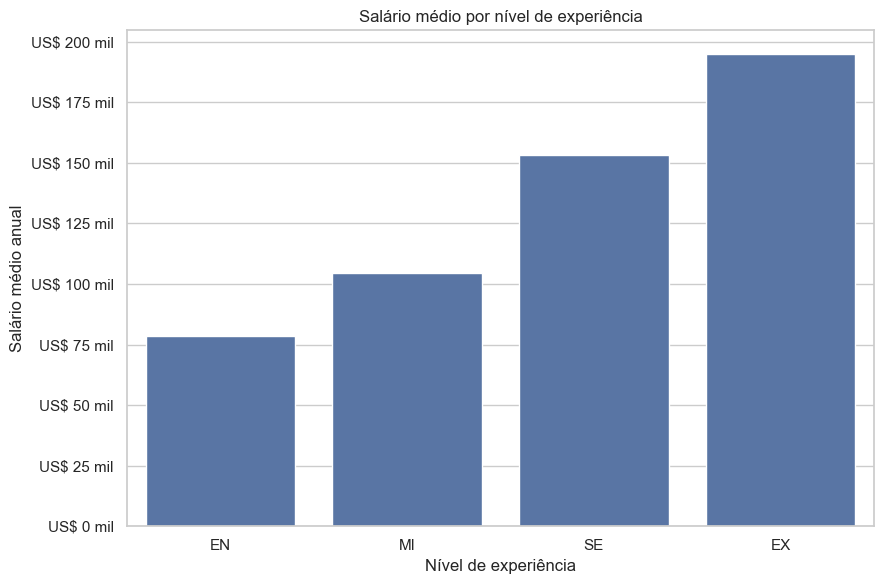

In [32]:
average_experience = (
    df.groupby("experience_level")["salary_in_usd"].mean().reindex(experience_order)
)

plt.figure(figsize=(9, 6))

sns.barplot(x=average_experience.index, y=average_experience.values)

plt.title(f"Salário médio por nível de experiência")
plt.xlabel(f"Nível de experiência")
plt.ylabel(f"Salário médio anual")

ax = plt.gca()

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"US$ {y / 1_000:.0f} mil"))

plt.tight_layout()
plt.show()

### 6.4 Salário mediano por nível de experiência

A mediana é especialmente útil em dados salariais por ser menos sensível a valores extremos.


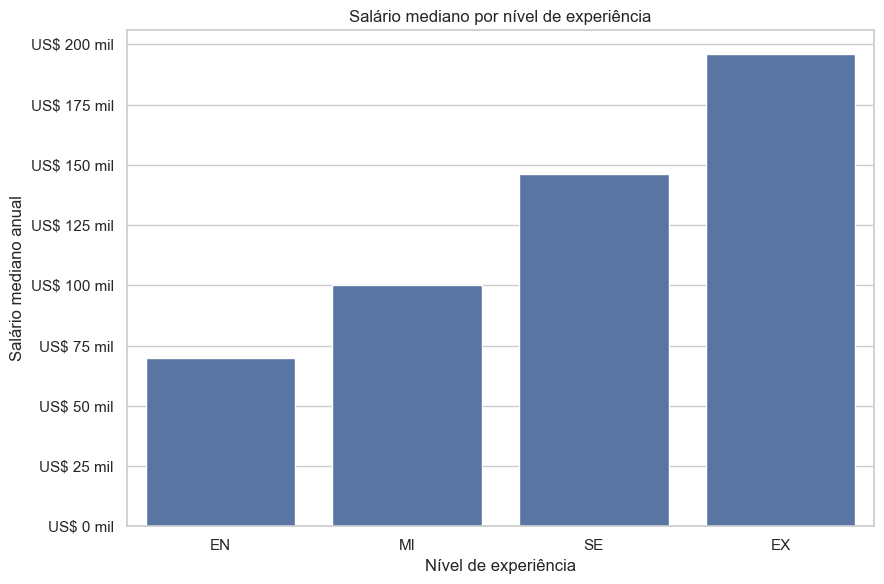

In [33]:
median_experience = (
    df.groupby("experience_level")["salary_in_usd"].median().reindex(experience_order)
)

plt.figure(figsize=(9, 6))

sns.barplot(x=median_experience.index, y=median_experience.values)

plt.title(f"Salário mediano por nível de experiência")
plt.xlabel(f"Nível de experiência")
plt.ylabel(f"Salário mediano anual")

ax = plt.gca()

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"US$ {y / 1_000:.0f} mil"))

plt.tight_layout()

plt.savefig("../images/salario_mediano_exp.png", dpi=300, bbox_inches="tight")

plt.show()

### 6.5 Distribuição salarial por nível de experiência

O boxplot permite comparar a mediana, dispersão e presença de valores extremos entre os níveis profissionais.


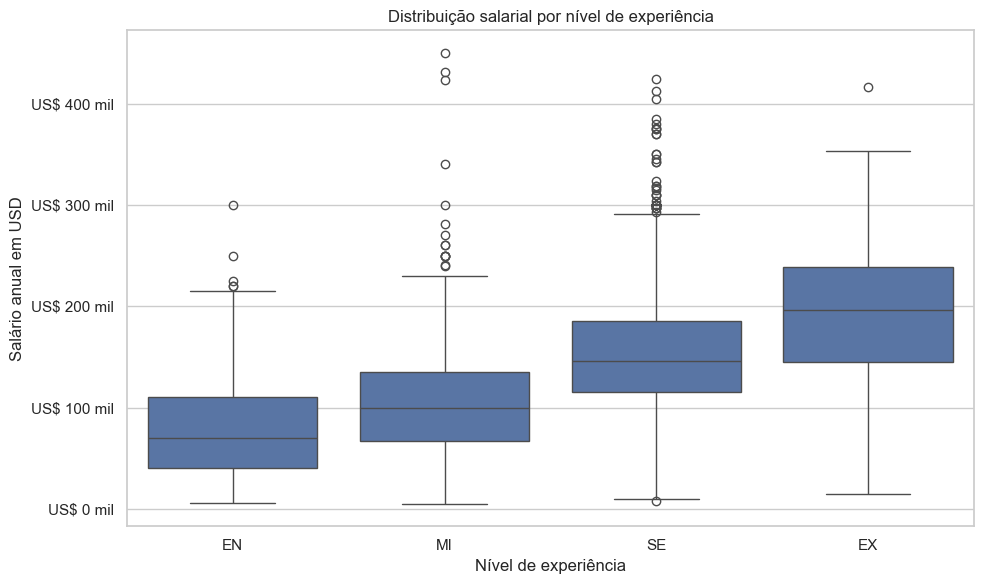

In [34]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="experience_level", y="salary_in_usd", order=experience_order)

plt.title(f"Distribuição salarial por nível de experiência")
plt.xlabel(f"Nível de experiência")
plt.ylabel(f"Salário anual em USD")

ax = plt.gca()

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"US$ {y / 1_000:.0f} mil"))

plt.tight_layout()
plt.show()

### 6.6 Diferença percentual entre medianas salariais

Para complementar a análise, será calculada a variação percentual da mediana salarial entre níveis consecutivos de experiência.


In [35]:
sorted_medians = (
    df.groupby("experience_level")["salary_in_usd"].median().reindex(experience_order)
)

median_variation = sorted_medians.pct_change() * 100

median_comparison = pd.DataFrame(
    {"Mediana": sorted_medians, "Variacao_Percentual": median_variation}
)

median_comparison

,Mediana,Variacao_Percentual
experience_level,,
EN,70000.0,NaN
MI,100000.0,42.857143
SE,146000.0,46.000000
EX,196000.0,34.246575


In [36]:
median_comparison_displey = median_comparison.copy()

median_comparison_displey["Mediana"] = median_comparison_displey["Mediana"].map(
    lambda x: f"US$ {x:,.2f}"
)

median_comparison_displey["Variacao_Percentual"] = median_comparison_displey[
    "Variacao_Percentual"
].map(lambda x: "-" if pd.isna(x) else f"{x:2f}%")

median_comparison_displey

,Mediana,Variacao_Percentual
experience_level,,
EN,"US$ 70,000.00",-
MI,"US$ 100,000.00",42.857143%
SE,"US$ 146,000.00",46.000000%
EX,"US$ 196,000.00",34.246575%


### 6.7 Interpretação da relação entre experiência e salário

Os resultados mostram uma progressão salarial consistente aumenta o nível de experiência profissional.

Profissionais classificados `EN` (Entry-level) apresentam salário médio de aproximadamente **US$ 78,5 mil** e mediana de **US$ 70 mil**.

No nível `MI` (Mid-level), a média salarial sobe para aproximadamente **US$ 104,5 mil**, enquanto a mediana alcança **US$ 100 mil**.

Entre profissionais `SE` (Senior), que representam a maior parte da base, o salário médio chega a aproximadamente **US$ 153,1 mil**, com mediana **US$ 146 mil**.

O maior nível de remuneração é observado entre profissionais `EX` (Executive), com salário médio de aproximadamente **US$ 194,9 mil** e mediana de **US$ 196 mil**.

A comparação das medianas evidencia aumentos relevantes entre os níveis:

- de `EN` para `MI`, a mediana salarial aumenta aproximadamente **42,86%**;
- de `MI` para `SE`, o aumento é de aproximadamente **46,00%**
- de `SE` para `EX`, a mediana cresce aproximadamente **34,25%**.

Os gráficos de média e mediana apresentam o mesmo padrão crescente, reforçando a associação positiva entre nível profissional e remuneração.

O boxplot também mostra um deslocamento progressivo da distribuição salarial para valores mais altos à medida que a senioridade aumenta. Embora existam valores extremos em diferentes níveis, o comportamento central das distribuições mantém uma progressão clara de `EN` até `EX`.

Esses resultados indicam uma forte associação entre maior nível de experiência e maiores salários na base analisada. Entretanto, essa relação deve ser interpretada como causalidade, pois outras características, como cargo, país e porte de empresa, também podem influenciar a remuneração.


## 7. Análise salarial por cargo

A base possui grande diversidade de funções profissionais, com 93 cargos distintos.

Entretanto, a quantidade de observações por cargo é desigual. Comparar diretamente salários de cargos com poucos registros pode gerar conclusões pouco representativas.

Por esse motivo, a análise será dividida entre:

- cargos mais frequentes da base;
- salários médios e medianos;
- número de observações de cada cargo;
- seleção de cargos com tamanho mínimo de amostra.


### 7.1 Cargos mais frequentes

Inicialmente, será analisada a frequência dos cargos para identificar quais funções possuem maior representatividade no conjunto de dados.


In [37]:
job_position_frequency = df["job_title"].value_counts().reset_index()

job_position_frequency.columns = ["Cargo", "Quantidade"]

job_position_frequency.head(15)

,Cargo,Quantidade
0,Data Engineer,1040
1,Data Scientist,840
2,Data Analyst,612
3,Machine Learning Engineer,289
4,Analytics Engineer,103
5,Data Architect,101
6,Research Scientist,82
7,Applied Scientist,58
8,Data Science Manager,58
9,Research Engineer,37


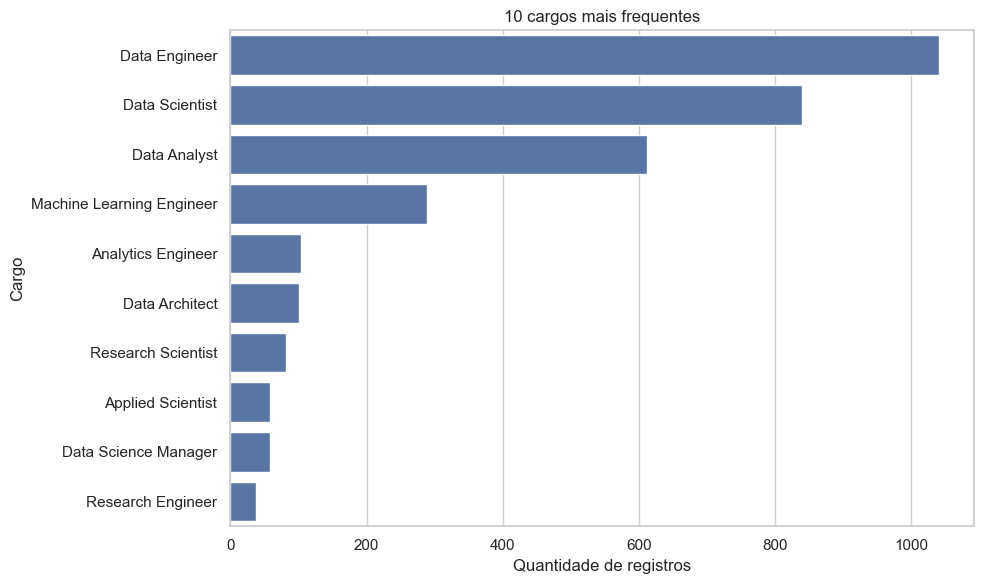

In [38]:
top_positions = job_position_frequency.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(data=top_positions, x="Quantidade", y="Cargo")
plt.title(f"10 cargos mais frequentes")
plt.xlabel(f"Quantidade de registros")
plt.ylabel(f"Cargo")

plt.tight_layout()
plt.show()

### 7.2 Seleção de cargos com amostra mínima

Para tornar as comparações salariais mais robustas, serão considerados inicialmente apenas cargos com pelo menos **30 registros** na base.

Esse critério reduz o risco de interpretar médias ou medianas calculadas a partir de um número muito pequeno de observações.


In [39]:
quantity_by_position = df["job_title"].value_counts()

valid_positions = quantity_by_position[quantity_by_position >= 30].index

df_valid_positions = df[df["job_title"].isin(valid_positions)].copy()

print(f"Cargos com pelo menos 30 registros: " f"{len(valid_positions)}")
print(f"Registros considerados: " f"{len(df_valid_positions):,}")

Cargos com pelo menos 30 registros: 11
Registros considerados: 3,254


### 7.3 Estatísticas salariais por cargo


In [40]:
salary_by_job_title = (
    df_valid_positions.groupby("job_title")["salary_in_usd"]
    .agg(Quantidade="count", Media="mean", Mediana="median", Minimo="min", Maximo="max")
    .reset_index()
    .sort_values("Mediana", ascending=False)
)

salary_by_job_title.head(15)

,job_title,Quantidade,Media,Mediana,Minimo,Maximo
1,Applied Scientist,58,190264.482759,191737.5,72000,350000
5,Data Science Manager,58,191278.775862,183780.0,54094,300000
3,Data Architect,101,161713.772277,160000.0,63000,376080
7,ML Engineer,34,158352.441176,160000.0,15966,289076
9,Research Engineer,37,163108.378378,155000.0,60000,293000
8,Machine Learning Engineer,289,154690.726644,150000.0,12000,342300
10,Research Scientist,82,161214.195122,150000.0,23000,450000
0,Analytics Engineer,103,152368.631068,143860.0,7500,289800
6,Data Scientist,840,140869.765476,141525.0,5679,412000
4,Data Engineer,1040,142785.734615,135000.0,12000,324000


In [41]:
salary_by_job_title_display = salary_by_job_title.head(15).copy()

for coluna in ["Media", "Mediana", "Minimo", "Maximo"]:
    salary_by_job_title_display[coluna] = salary_by_job_title_display[coluna].map(
        lambda x: f"US$ {x:,.2f}"
    )

salary_by_job_title_display

,job_title,Quantidade,Media,Mediana,Minimo,Maximo
1,Applied Scientist,58,"US$ 190,264.48","US$ 191,737.50","US$ 72,000.00","US$ 350,000.00"
5,Data Science Manager,58,"US$ 191,278.78","US$ 183,780.00","US$ 54,094.00","US$ 300,000.00"
3,Data Architect,101,"US$ 161,713.77","US$ 160,000.00","US$ 63,000.00","US$ 376,080.00"
7,ML Engineer,34,"US$ 158,352.44","US$ 160,000.00","US$ 15,966.00","US$ 289,076.00"
9,Research Engineer,37,"US$ 163,108.38","US$ 155,000.00","US$ 60,000.00","US$ 293,000.00"
8,Machine Learning Engineer,289,"US$ 154,690.73","US$ 150,000.00","US$ 12,000.00","US$ 342,300.00"
10,Research Scientist,82,"US$ 161,214.20","US$ 150,000.00","US$ 23,000.00","US$ 450,000.00"
0,Analytics Engineer,103,"US$ 152,368.63","US$ 143,860.00","US$ 7,500.00","US$ 289,800.00"
6,Data Scientist,840,"US$ 140,869.77","US$ 141,525.00","US$ 5,679.00","US$ 412,000.00"
4,Data Engineer,1040,"US$ 142,785.73","US$ 135,000.00","US$ 12,000.00","US$ 324,000.00"


### 7.4 Interpretação da frequência dos cargos

A distribuição dos cargos mostra forte concentração em algumas funções.

`Data Engineer`, `Data Scientist` e `Data Analyst` representam, de forma isolada, uma parcela significativa da base, enquanto diversos outros cargos possuem quantidade muito menor de observações.

Essa concentração reforça a necessidade de considerar o tamanho da amostra antes de comparar salários entre funções.

Para reduzir o risco de interpretações baseadas em poucos registros, a análise salarial foi restringida inicialmente aos cargos com pelo menos 30 observações.

Com esse critério, foram mantidos **11 cargos**, totalizando **3.254 registros**.


### 7.5 Interpretação dos salários por cargo

Entre os cargos com pelo menos 30 registros, observa-se diferença relevante nas remunerações.

Os maiores valores de mediana foram encontrados em:

- `Applied Scientist`: aproximadamente **US$ 191,7 mil**;
- `Data Science Manager`: aproximadamente **US$ 183,8 mil**;
- `Data Architect`: aproximadamente **US$ 160 mil**;
- `ML Engineer`: aproximadamente **US$ 160 mil**;
- `Research Engineer`: aproximadamente **US$ 155 mil**.

Na outra extremidade, entre os cargos analisados:

- `Data Analyst` apresentou mediana de aproximadamente **US$ 106 mil**;
- `Data Engineer`, mediana de aproximadamente **US$ 135 mil**;
- `Data Scientist`, mediana de aproximadamente **US$ 141,5 mil**.

Esses resultados mostram que funções ligadas a maior especialização técnica, pesquisa aplicada, arquitetura e gestão tendem a apresentar remunerações mais elevadas dentro da base.

Entretanto, a comparação salarial entre cargos deve ser interpretada com cautela, pois fatores como experiência, localização geográfica, porte da empresa e ano do registro também podem influenciar os salários.


# 8. Análise salarial por localização

Nesta etapa será investigado a relaçã entre localização geográfica e remuneração.

A análise será realizada em dois níveis:

- região;
- país.

Como a quantidade de observações varia bastante entre os grupos geográficos, serão considerados também o tamanho da amostra, a média e a mediana salarial.


### 8.1 Estatísticas salarias por região

Primeiro, serão comparados os salários entre as regiões presentes na base.


In [42]:
salary_by_region = (
    df.groupby("region")["salary_in_usd"]
    .agg(Quantidade="count", Media="mean", Mediana="median", Minimo="min", Maximo="max")
    .reset_index()
    .sort_values("Mediana", ascending=False)
)

salary_by_region

,region,Quantidade,Media,Mediana,Minimo,Maximo
1,Americas,3140,150915.876115,145000.0,6270,450000
4,Oceania,14,74881.500000,71684.0,20000,150000
3,Europe,464,74852.359914,65929.0,5132,430967
2,Asia,120,50661.400000,30475.5,5409,423834
0,Africa,17,49515.235294,30469.0,7000,200000


In [43]:
salary_by_region_display = salary_by_region.copy()

for coluna in ["Media", "Mediana", "Minimo", "Maximo"]:
    salary_by_region_display[coluna] = salary_by_region_display[coluna].map(
        lambda x: f"US$ {x:,.2f}"
    )

salary_by_region_display

,region,Quantidade,Media,Mediana,Minimo,Maximo
1,Americas,3140,"US$ 150,915.88","US$ 145,000.00","US$ 6,270.00","US$ 450,000.00"
4,Oceania,14,"US$ 74,881.50","US$ 71,684.00","US$ 20,000.00","US$ 150,000.00"
3,Europe,464,"US$ 74,852.36","US$ 65,929.00","US$ 5,132.00","US$ 430,967.00"
2,Asia,120,"US$ 50,661.40","US$ 30,475.50","US$ 5,409.00","US$ 423,834.00"
0,Africa,17,"US$ 49,515.24","US$ 30,469.00","US$ 7,000.00","US$ 200,000.00"


### 8.2 Salário mediano por região

A mediana será utilizada como principal referência visual por ser menos sensível a salários extremamente altos.

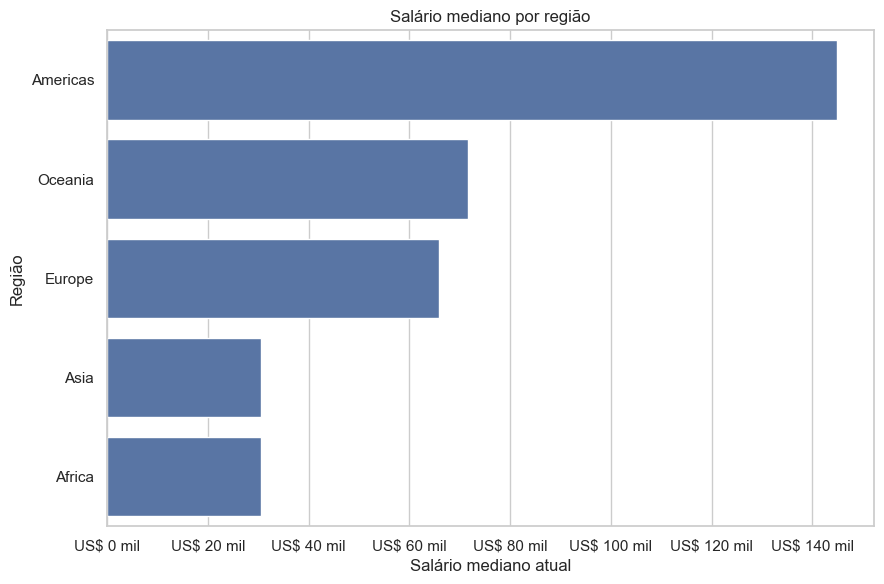

In [44]:
region_order = salary_by_region.sort_values("Mediana", ascending=False)["region"]

plt.figure(figsize=(9, 6))

sns.barplot(data=salary_by_region, x="Mediana", y="region", order=region_order)

plt.title(f"Salário mediano por região")
plt.xlabel(f"Salário mediano atual")
plt.ylabel(f"Região")

ax = plt.gca()

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"US$ {x / 1_000:.0f} mil"))

plt.tight_layout()

plt.savefig("../images/salario_mediano_regiao.png", dpi=300, bbox_inches="tight")

plt.show()

### 8.3 Distribuição salarial por região

O boxplot permite observar não apenas o valor central dos salários, mas também a dispersão e a presença de valores extremos em cada região.

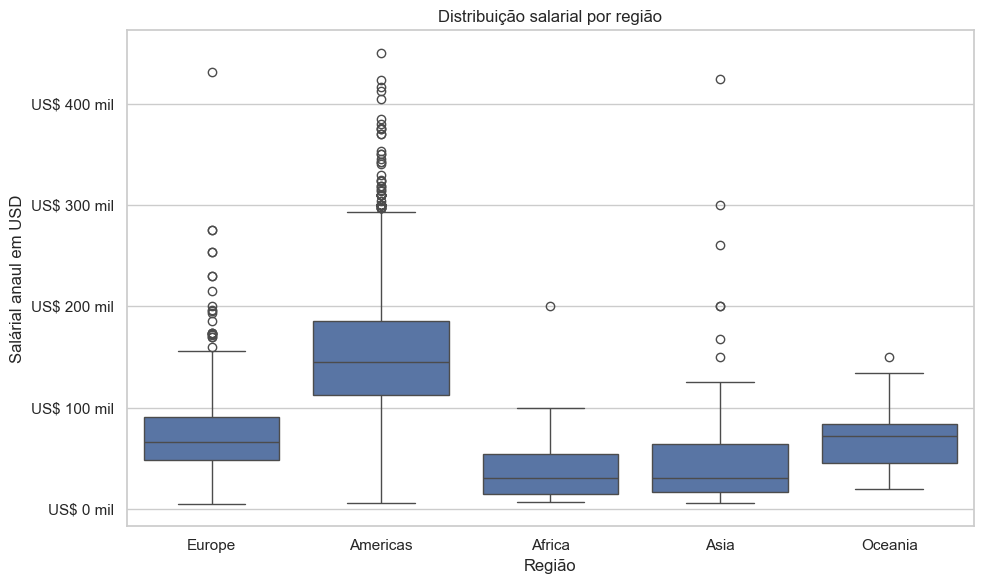

In [45]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="region", y="salary_in_usd")

plt.title(f"Distribuição salarial por região")
plt.xlabel(f"Região")
plt.ylabel(f"Salárial anaul em USD")

ax = plt.gca()

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"US$ {y / 1_000:.0f} mil"))

plt.tight_layout()
plt.show()

### 8.4 Distribuição dos registros por país

Como a base possui muitos países, primeiro será analisada a quantidade de registros disponíveis em cada um.

In [46]:
country_frequency = df["country"].value_counts().reset_index()

country_frequency.columns = ["Pais", "Quantidade"]

country_frequency.head(15)

,Pais,Quantidade
0,United States of America,3004
1,United Kingdom of Great Britain and Northern I...,167
2,Canada,85
3,Spain,80
4,India,71
5,Germany,48
6,France,38
7,Portugal,18
8,Brazil,18
9,Greece,16


### 8.5 Seleção de países com amostra mínima

Para evitar comparações baseadas em poucos registros, serão considerados inicialmente apenas países com pelo menos **30 observações**.

In [47]:
quantity_by_country = df["country"].value_counts()

valid_countries = quantity_by_country[quantity_by_country >= 30].index

df_valid_countries = df[df["country"].isin(valid_countries)].copy()

print(f"Países com pelo menos 30 registros: " f"{len(valid_countries)}")
print(f"Registros considerados: " f"{len(df_valid_countries):,}")

Países com pelo menos 30 registros: 7
Registros considerados: 3,493


### 8.6 Estatísticas salarias por país 

Serão comparados quantidade de registros, média e mediana salarial entre os países com amostra suficiente.

In [48]:
salary_by_country = (
    df_valid_countries.groupby("country")["salary_in_usd"]
    .agg(Quantidade="count", Media="mean", Mediana="median", Minimo="min", Maximo="max")
    .reset_index()
    .sort_values("Mediana", ascending=False)
)

salary_by_country

,country,Quantidade,Media,Mediana,Minimo,Maximo
6,United States of America,3004,152822.011651,145000.0,24000,450000
0,Canada,85,132222.905882,120000.0,10000,275000
5,United Kingdom of Great Britain and Northern I...,167,86988.323353,80036.0,30000,430967
2,Germany,48,94772.250000,76833.0,15966,275000
1,France,38,61492.500000,58969.5,6359,115573
4,Spain,80,60463.350000,47281.0,10354,253750
3,India,71,36218.450704,20670.0,5409,300000


In [49]:
salary_by_country_display = salary_by_country.copy()

for col in ["Media", "Mediana", "Minimo", "Maximo"]:
    salary_by_country_display[col] = salary_by_country_display[col].map(
        lambda x: f"US$ {x:,.2f}"
    )

salary_by_country_display

,country,Quantidade,Media,Mediana,Minimo,Maximo
6,United States of America,3004,"US$ 152,822.01","US$ 145,000.00","US$ 24,000.00","US$ 450,000.00"
0,Canada,85,"US$ 132,222.91","US$ 120,000.00","US$ 10,000.00","US$ 275,000.00"
5,United Kingdom of Great Britain and Northern I...,167,"US$ 86,988.32","US$ 80,036.00","US$ 30,000.00","US$ 430,967.00"
2,Germany,48,"US$ 94,772.25","US$ 76,833.00","US$ 15,966.00","US$ 275,000.00"
1,France,38,"US$ 61,492.50","US$ 58,969.50","US$ 6,359.00","US$ 115,573.00"
4,Spain,80,"US$ 60,463.35","US$ 47,281.00","US$ 10,354.00","US$ 253,750.00"
3,India,71,"US$ 36,218.45","US$ 20,670.00","US$ 5,409.00","US$ 300,000.00"


### 8.7 Gráfico da mediana por país

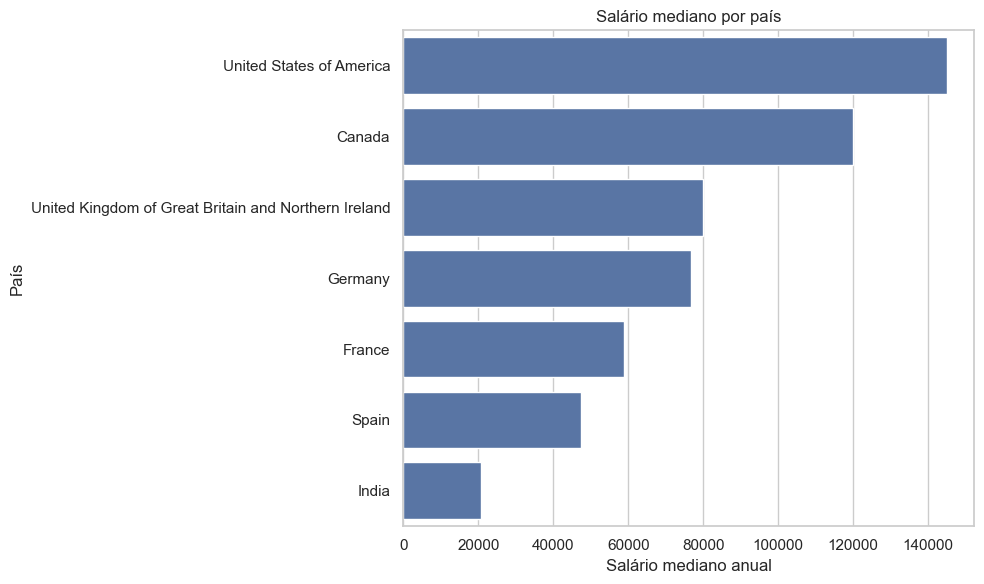

In [50]:
plt.figure(figsize=(10, 6))

sns.barplot(data=salary_by_country, x="Mediana", y="country")

plt.title(f"Salário mediano por país")
plt.xlabel(f"Salário mediano anual")
plt.ylabel(f"País")

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"US$ {x / 1_000:.0f} mil"))

plt.tight_layout()
plt.show()

### 8.8 Interpretação da relação entre localização e salário

A análise geográfica mostra diferenças relevantes nos níveis de remuneração entre regiões e países.

Entre as regiões, `Americas` apresentou a maior mediana salarial, de aproximadamente **US$ 145 mil**, seguida por `Oceania`, com aproximadamente **US$ 71,7 mil**, e `Europe`, com aproximadamente **US$ 65,9 mil**.

`Asia` e `Africa` apresentaram medianas próximas de **US$ 30,5 mil**.

Entretanto, essas comparações devem ser interpretadas com cautela devido à forte diferença no tamanho das amostras. A região `Americas` possui **3.140 registros**, enquanto `Oceania` e `Africa` possuem apenas **14 e 17 observações**, respectivamente.

Além disso, a região das Américas é fortemente influenciada pelos Estados Unidos, que representam a maior parte das observações dessa categoria.

Para reduzir o impacto de países com poucas observações, a comparação por país considerou apenas locais com pelo menos 30 registros.

Nesse grupo, os maiores salários medianos foram observados em:

- Estados Unidos: aproximadamente **US$ 145 mil**;
- Canadá: aproximadamente **US$ 120 mil**;
- Reino Unido: aproximadamente **US$ 80 mil**;
- Alemanha: aproximadamente **US$ 76,8 mil**.

Na outra extremidade, a Índia apresentou mediana salarial de aproximadamente **US$ 20,7 mil**.

Os resultados evidenciam uma forte associação entre localização geográfica e remuneração na base analisada. Entretanto, essas diferenças não devem ser interpretadas isoladamente, pois fatores como nível de experiência, cargo, porte da empresa e composição da amostra também podem influenciar os salários.

## 9. Análise salarial por porte da empresa

Nesta etapa será analisada a relação entre o porte da empresa e a remuneração dos profissionais.

A variável `company_size` possui três categorias:

- `S`: empresa pequena;
- `M`: empresa média;
- `L`: empresa grande.

Como a quantidade de registros é bastante diferente entre os grupos, o tamanho da amostra também será considerado na interpretação.

### 9.1 Estatísticas salariais por porte da empresa

Serão comparados quantidade de registros, média, mínimo, máximo e dispersão salarial entre os diferentes portes de empresa.

In [51]:
salary_by_company = (
    df.groupby("company_size")["salary_in_usd"]
    .agg(
        Quantidade="count",
        Media="mean",
        Mediana="median",
        Minimo="min",
        Maximo="max",
        Desvio_Padrao="std",
    )
    .reset_index()
)

salary_by_company

,company_size,Quantidade,Media,Mediana,Minimo,Maximo,Desvio_Padrao
0,L,454,118300.982379,108500.0,5409,423834,75832.391505
1,M,3153,143130.548367,140000.0,5132,450000,58992.813382
2,S,148,78226.682432,62146.0,5679,416000,61955.141792


In [52]:
salary_by_company_display = salary_by_company.copy()

for col in ["Media", "Mediana", "Minimo", "Maximo", "Desvio_Padrao"]:
    salary_by_company_display[col] = salary_by_company_display[col].map(
        lambda x: f"US$ {x:,.2f}"
    )

salary_by_company_display

,company_size,Quantidade,Media,Mediana,Minimo,Maximo,Desvio_Padrao
0,L,454,"US$ 118,300.98","US$ 108,500.00","US$ 5,409.00","US$ 423,834.00","US$ 75,832.39"
1,M,3153,"US$ 143,130.55","US$ 140,000.00","US$ 5,132.00","US$ 450,000.00","US$ 58,992.81"
2,S,148,"US$ 78,226.68","US$ 62,146.00","US$ 5,679.00","US$ 416,000.00","US$ 61,955.14"


### 9.2 Salário mediano por porte da empresa

A mediana será utilizada como principal medida de comparação por ser menos sensível aos valores salariais extremos.

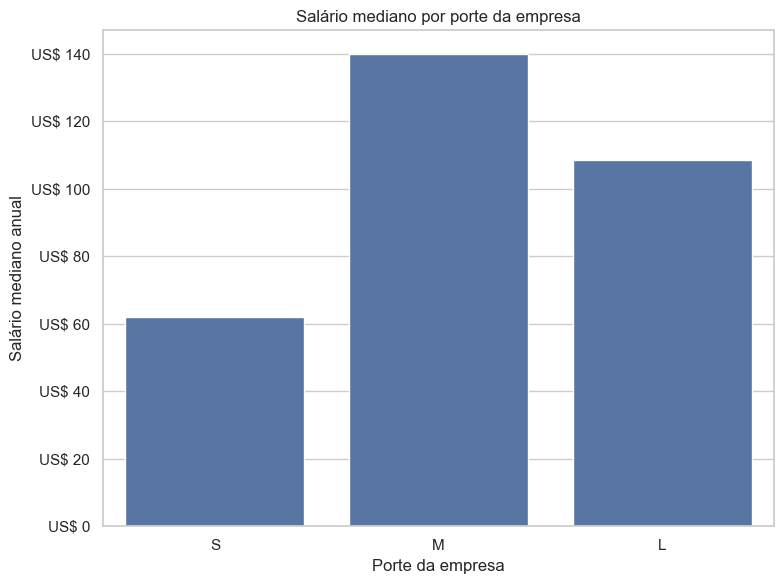

In [53]:
company_order = ["S", "M", "L"]

medium_sized_enterprise = (
    df.groupby("company_size")["salary_in_usd"].median().reindex(company_order)
)

plt.figure(figsize=(8, 6))

sns.barplot(x=medium_sized_enterprise.index, y=medium_sized_enterprise.values)

plt.title(f"Salário mediano por porte da empresa")
plt.xlabel(f"Porte da empresa")
plt.ylabel(f"Salário mediano anual")

ax = plt.gca()

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"US$ {y / 1_000:.0f}"))

plt.tight_layout()

plt.savefig("../images/salario_mediano_empresa.png", dpi=300, bbox_inches="tight")

plt.show()

### 9. 3 Distribuição salarial por porte da empresa

O boxplot permite comparar a distrinuição, mediana, dispersão e valores extremos entre empresas pequenas, médias e grandes.

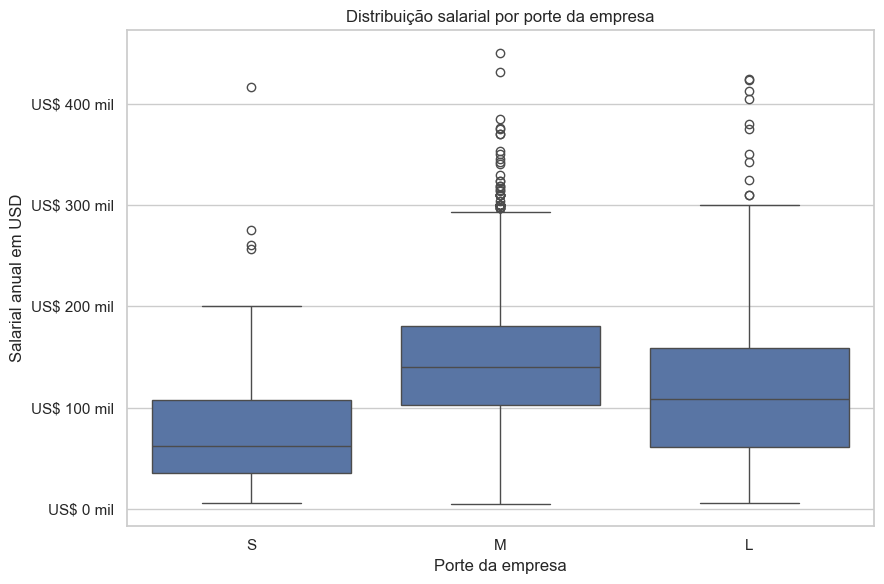

In [54]:
plt.figure(figsize=(9, 6))

sns.boxplot(data=df, x="company_size", y="salary_in_usd", order=company_order)

plt.title(f"Distribuição salarial por porte da empresa")
plt.xlabel(f"Porte da empresa")
plt.ylabel(f"Salarial anual em USD")

ax = plt.gca()

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"US$ {y / 1_000:.0f} mil"))

plt.tight_layout()
plt.show()

### 9.4 Diferença percentual entre medianas

Para complementar a comparação, será calculada a diferença percentual entre as medianas salariais dos diferentes portes de empresa.

In [55]:
company_medians = (
    df.groupby("company_size")["salary_in_usd"].median().reindex(company_order)
)

company_variation = company_medians.pct_change() * 100

company_comparison = pd.DataFrame(
    {"Mediana": company_medians, "Variacao_Percentual": company_variation}
)

company_comparison

,Mediana,Variacao_Percentual
company_size,,
S,62146.0,NaN
M,140000.0,125.275963
L,108500.0,-22.500000


In [56]:
company_comparison_display = company_comparison.copy()

company_comparison_display["Mediana"] = company_comparison_display["Mediana"].map(
    lambda x: f"US$ {x:,.2f}"
)

company_comparison_display["Variacao_Percentual"] = company_comparison_display[
    "Variacao_Percentual"
].map(lambda x: "-" if pd.isna(x) else f"{x:.2f}%")

company_comparison_display

,Mediana,Variacao_Percentual
company_size,,
S,"US$ 62,146.00",-
M,"US$ 140,000.00",125.28%
L,"US$ 108,500.00",-22.50%


### 9.5 Interpretação da relação entre porte da empresa e salário

Os resultados mostram diferenças relevantes de remuneração entre os diferentes portes de empresa.

Profissionais de empresas pequenas (`S`) apresentaram salário mediano de aproximadamente **US$ 62,1 mil**.

Nas empresas médias (`M`), a mediana salarial aumentou para aproximadamente **US$ 140 mil**, representando uma elevação de cerca de **125,28%** em relação às empresas pequenas.

Entretanto, nas empresas grandes (`L`), a mediana foi de aproximadamente **US$ 108,5 mil**, valor cerca de **22,50% inferior** ao observado nas empresas médias.

Esse comportamento mostra que, dentro desta base, o aumento do porte da empresa não está associado a uma progressão salarial linear.

As empresas médias concentram os maiores salários centrais, enquanto empresas grandes apresentam remuneração superior às pequenas, mas inferior às médias.

O boxplot reforça essa diferença, mostrando que empresas médias possuem uma distribuição salarial deslocada para valores mais altos e também apresentam diversos salários extremos superiores.

Entretanto, essa comparação deve ser interpretada com cautela. A quantidade de observações é bastante desigual entre os grupos: empresas médias representam a grande maioria da base, com 3.153 registros, enquanto empresas grandes possuem 454 registros e empresas pequenas apenas 148.

Além disso, fatores como nível de experiência, cargo e localização podem influenciar simultaneamente a remuneração. Portanto, os resultados mostram uma associação entre porte da empresa e salário, mas não permitem concluir que o porte da empresa, isoladamente, seja responsável pelas diferenças observadas.

## 10. Análise salarial por anos de experiência

Nesta etapa será investigada a relação entre a quantidade de anos de experiência profissional e o salário anual.

Diferentemente de `experience_level`, que representa categorias de senioridade, `years_of_experience` permite analisar a experiência em uma escala numérica.

Serão avaliados:

- quantidade de registros por ano de experiência;
- média e mediana salarial;
- evolução salarial ao longo da experiência;
- relação estatística entre experiência e salário.

### 10.1 Distribuição dos registros por anos de experiência

In [57]:
experience_frequency = (
    df["years_of_experience"].value_counts().sort_index().reset_index()
)

experience_frequency.columns = ["Anos_Experiencia", "Quantidade"]

experience_frequency

,Anos_Experiencia,Quantidade
0,1,172
1,2,148
2,3,250
3,4,283
4,5,272
5,6,838
6,7,821
7,8,857
8,9,60
9,10,54


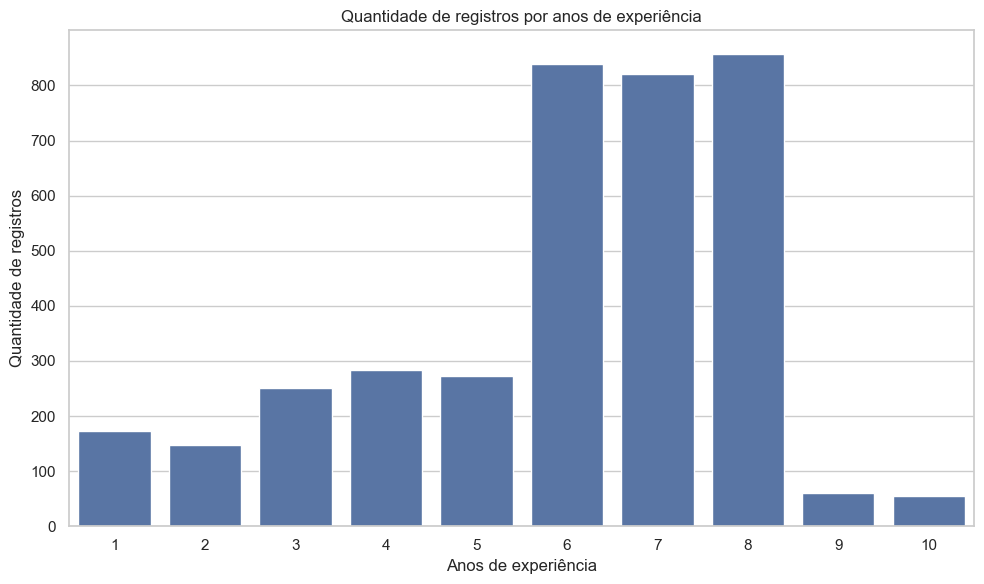

In [58]:
plt.figure(figsize=(10, 6))

sns.barplot(data=experience_frequency, x="Anos_Experiencia", y="Quantidade")

plt.title(f"Quantidade de registros por anos de experiência")
plt.xlabel(f"Anos de experiência")
plt.ylabel(f"Quantidade de registros")

plt.tight_layout()
plt.show()

### 10.2 Estatísticas salarias por anos de experiência

Serão calculadas a quantidade de registros, média e mediana salarial para cada nível de experiência em anos.

In [59]:
salary_by_years = (
    df.groupby("years_of_experience")["salary_in_usd"]
    .agg(Quantidade="count", Media="mean", Mediana="median", Minimo="min", Maximo="max")
    .reset_index()
)

salary_by_years

,years_of_experience,Quantidade,Media,Mediana,Minimo,Maximo
0,1,172,79011.470930,70000.0,5409,300000
1,2,148,78005.662162,70000.0,5707,250000
2,3,250,102550.200000,96109.0,5132,423000
3,4,283,104964.003534,100000.0,5409,450000
4,5,272,105886.095588,100000.0,5679,430967
5,6,838,152635.869928,148000.0,15806,423834
6,7,821,153961.920828,150000.0,8000,385000
7,8,857,152584.480747,145000.0,12608,405000
8,9,60,200426.250000,200000.0,15000,416000
9,10,54,188825.018519,181080.0,76309,329500


In [60]:
salary_by_years_display = salary_by_years.copy()

for col in ["Media", "Mediana", "Minimo", "Maximo"]:
    salary_by_years_display[col] = salary_by_years_display[col].map(
        lambda x: f"US$ {x:,.2f}"
    )

salary_by_years_display

,years_of_experience,Quantidade,Media,Mediana,Minimo,Maximo
0,1,172,"US$ 79,011.47","US$ 70,000.00","US$ 5,409.00","US$ 300,000.00"
1,2,148,"US$ 78,005.66","US$ 70,000.00","US$ 5,707.00","US$ 250,000.00"
2,3,250,"US$ 102,550.20","US$ 96,109.00","US$ 5,132.00","US$ 423,000.00"
3,4,283,"US$ 104,964.00","US$ 100,000.00","US$ 5,409.00","US$ 450,000.00"
4,5,272,"US$ 105,886.10","US$ 100,000.00","US$ 5,679.00","US$ 430,967.00"
5,6,838,"US$ 152,635.87","US$ 148,000.00","US$ 15,806.00","US$ 423,834.00"
6,7,821,"US$ 153,961.92","US$ 150,000.00","US$ 8,000.00","US$ 385,000.00"
7,8,857,"US$ 152,584.48","US$ 145,000.00","US$ 12,608.00","US$ 405,000.00"
8,9,60,"US$ 200,426.25","US$ 200,000.00","US$ 15,000.00","US$ 416,000.00"
9,10,54,"US$ 188,825.02","US$ 181,080.00","US$ 76,309.00","US$ 329,500.00"


### 10.3 Evolução do salário mediano

A mediana salarial será utilizada para visualizar como a remuneração evolui conforme aumentam os anos de experiência profissional.

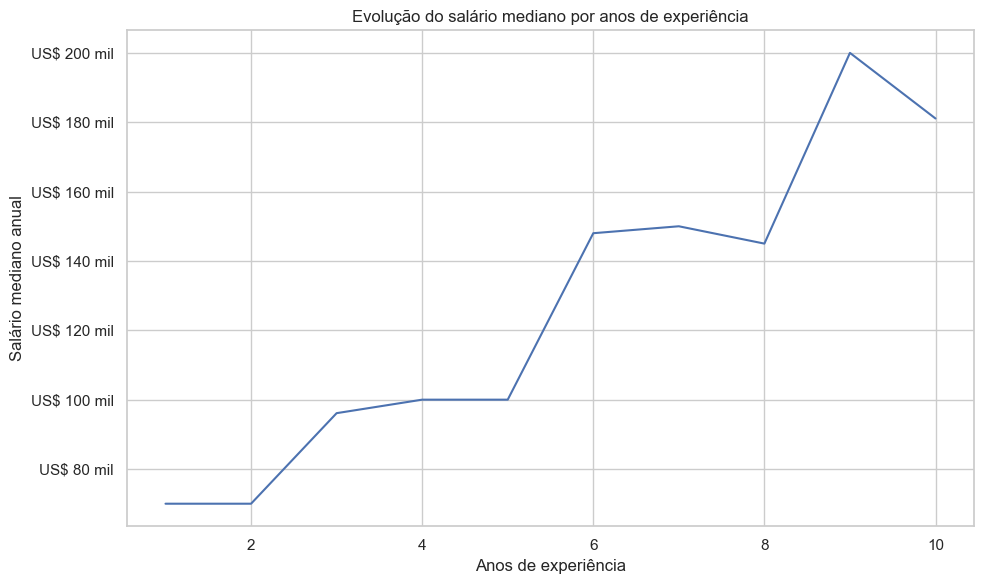

In [61]:
plt.figure(figsize=(10, 6))

sns.lineplot(data=salary_by_years, x="years_of_experience", y="Mediana", markers="o")

plt.title(f"Evolução do salário mediano por anos de experiência")
plt.xlabel(f"Anos de experiência")
plt.ylabel(f"Salário mediano anual")

ax = plt.gca()

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"US$ {y / 1_000:.0f} mil"))

plt.tight_layout()
plt.show()

### 10.4 Relação entre anos de experiência e salário

O gráfico de dispersão permite observar a relação entre experiência profissional e remuneração em nível individual.

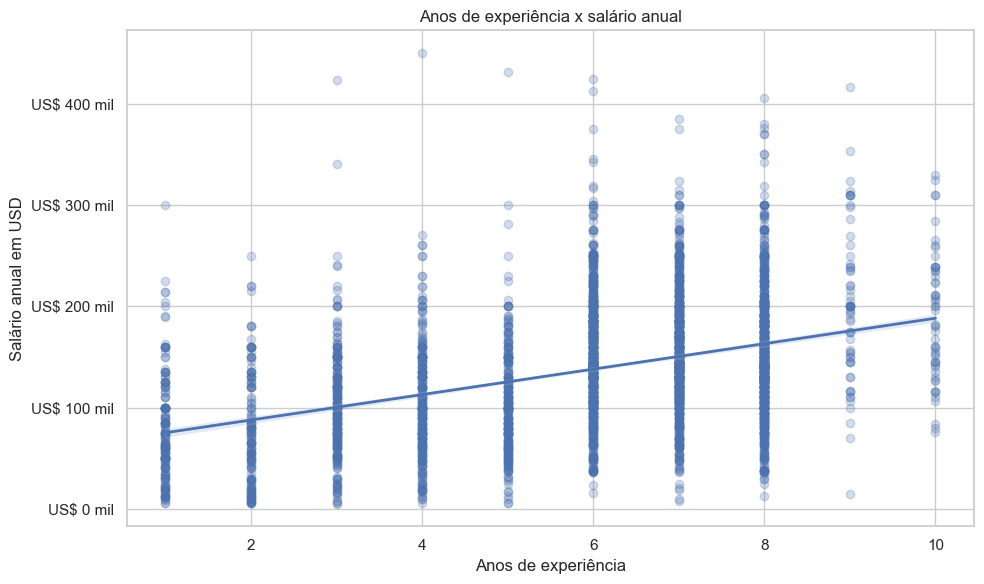

In [62]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="years_of_experience",
    y="salary_in_usd",
    scatter_kws={"alpha": 0.25},
    line_kws={"linewidth": 2},
)

plt.title(f"Anos de experiência x salário anual")
plt.xlabel(f"Anos de experiência")
plt.ylabel(f"Salário anual em USD")

ax = plt.gca()

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"US$ {y / 1_000:.0f} mil"))

plt.tight_layout()
plt.show()

### 10.5 Correlação entre experiência e salário

A correlação de Pearson será utilizada como medida complementar para valiar a força da associação linear entre anos de experiência e salário.

In [63]:
corr_experiencia_salary = (
    df[["years_of_experience", "salary_in_usd"]]
    .corr()
    .loc["years_of_experience", "salary_in_usd"]
)

print(
    f"Correlação entre anos de experiência "
    f"e salário: "
    f"{corr_experiencia_salary:.4f}"
)

Correlação entre anos de experiência e salário: 0.4107


### 10.6 Interpretação da relação entre anos de experiência e salário

Os resultados mostram uma associação positiva entre experiência profissional e remuneração.

De forma geral, os salários medianos aumentam à medida que crescem os anos de experiência.

Nos primeiros níveis, profissionais com 1 e 2 anos de experiência apresentam mediana salarial de aproximadamente **US$ 70 mil**.

A partir de 3 anos, observa-se uma elevação para aproximadamente **US$ 96,1 mil**, chegando a **US$ 100 mil** entre profissionais com 4 e 5 anos de experiência.

Um aumento mais expressivo aparece a partir de 6 anos, quando a mediana salarial alcança aproximadamente **US$ 148 mil**, permanecendo em patamar semelhante entre 7 e 8 anos.

Entre profissionais com 9 anos de experiência, a mediana chega a aproximadamente **US$ 200 mil**, enquanto aqueles com 10 anos apresentam mediana de aproximadamente **US$ 181 mil**.

Essa pequena redução no último grupo mostra que a relação entre experiência e salário não é perfeitamente crescente em todos os pontos. Além disso, os grupos com 9 e 10 anos possuem apenas 60 e 54 observações, respectivamente, o que exige maior cautela na interpretação.

A correlação de Pearson entre `years_of_experience` e `salary_in_usd` foi de **0,4107**, indicando uma **associação linear positiva moderada**.

O gráfico de dispersão também reforça essa tendência positiva, embora exista ampla variação salarial entre profissionais com a mesma quantidade de anos de experiência.

Isso sugere que a experiência profissional está associada ao salário, mas não explica isoladamente as diferenças de remuneração. Outras características, como cargo, nível de senioridade, localização e porte da empresa, também parecem influenciar os valores observados.

# 11. Evolução salarial ao longo dos anos

Nesta etapa será analisada a evolução entre 2020 a 2023.

Como a quantidade de registros varia bastante entre os anos, a análise considerará:

- quantidade de observações;
- salário médio;
- salário mediano;
- mínimo e máximo;
- evolução percentual da mediana.

### 11.1 Estatísticas salarias por ano

Serão comparadas as principais medidas salarias para cada ano presente na base.

In [64]:
salary_by_years = (
    df.groupby("work_year")["salary_in_usd"]
    .agg(
        Quantidade="count",
        Media="mean",
        Mediana="median",
        Minimo="min",
        Maximo="max",
        Desvio_Padrao="std",
    )
    .reset_index()
    .sort_values("work_year")
)

salary_by_years

,work_year,Quantidade,Media,Mediana,Minimo,Maximo,Desvio_Padrao
0,2020,76,92302.631579,73065.0,5707,450000,82370.048002
1,2021,230,94087.208696,80000.0,5409,423000,68600.465120
2,2022,1664,133338.620793,131300.0,5132,430967,58947.155520
3,2023,1785,149045.541176,143860.0,7000,423834,61307.711442


In [65]:
salary_by_years_display = salary_by_years.copy()

for col in ["Media", "Mediana", "Minimo", "Maximo", "Desvio_Padrao"]:
    salary_by_years_display[col] = salary_by_years_display[col].map(
        lambda x: f"US$ {x:,.2f}"
    )

salary_by_years_display

,work_year,Quantidade,Media,Mediana,Minimo,Maximo,Desvio_Padrao
0,2020,76,"US$ 92,302.63","US$ 73,065.00","US$ 5,707.00","US$ 450,000.00","US$ 82,370.05"
1,2021,230,"US$ 94,087.21","US$ 80,000.00","US$ 5,409.00","US$ 423,000.00","US$ 68,600.47"
2,2022,1664,"US$ 133,338.62","US$ 131,300.00","US$ 5,132.00","US$ 430,967.00","US$ 58,947.16"
3,2023,1785,"US$ 149,045.54","US$ 143,860.00","US$ 7,000.00","US$ 423,834.00","US$ 61,307.71"


### 11.2 Evolução do salário mediano

A mediana será utilizada como principal medida para acompanhar a evolução salarial ao longo do tempo, por ser menos sensível a valores extremos.

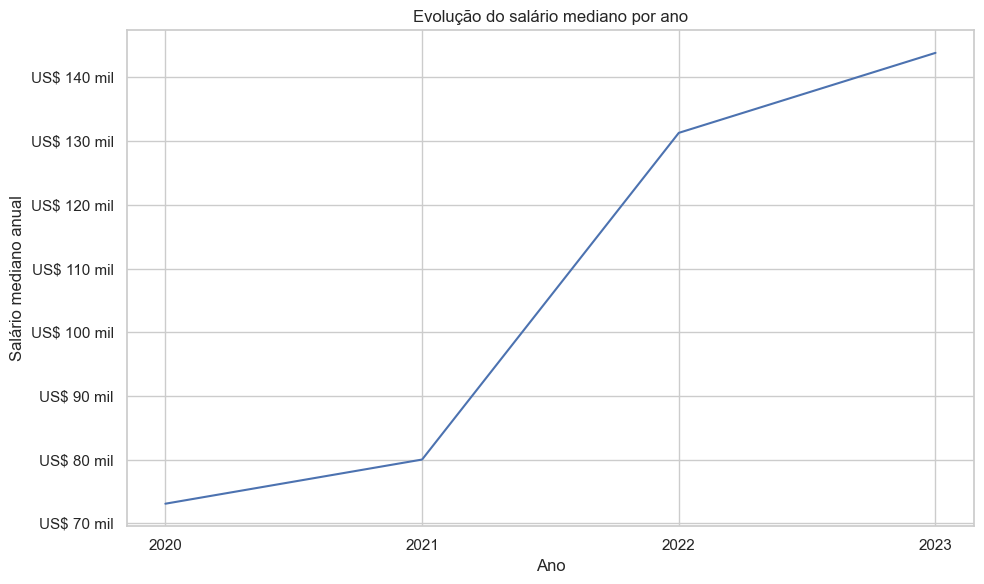

In [66]:
plt.figure(figsize=(10, 6))

sns.lineplot(data=salary_by_years, x="work_year", y="Mediana", markers="o")

plt.title(f"Evolução do salário mediano por ano")
plt.xlabel(f"Ano")
plt.ylabel(f"Salário mediano anual")
plt.xticks(salary_by_years["work_year"])

ax = plt.gca()

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"US$ {y / 1_000:.0f} mil"))

plt.tight_layout()

plt.savefig("../images/evolução_salario_mediano.png", dpi=300, bbox_inches="tight")

plt.show()

### 11.3 Evolução do salário médio

A média será analisada em conjunto com a mediana para verificar se valores extremos influenciam de forma relevante a tendência anual.

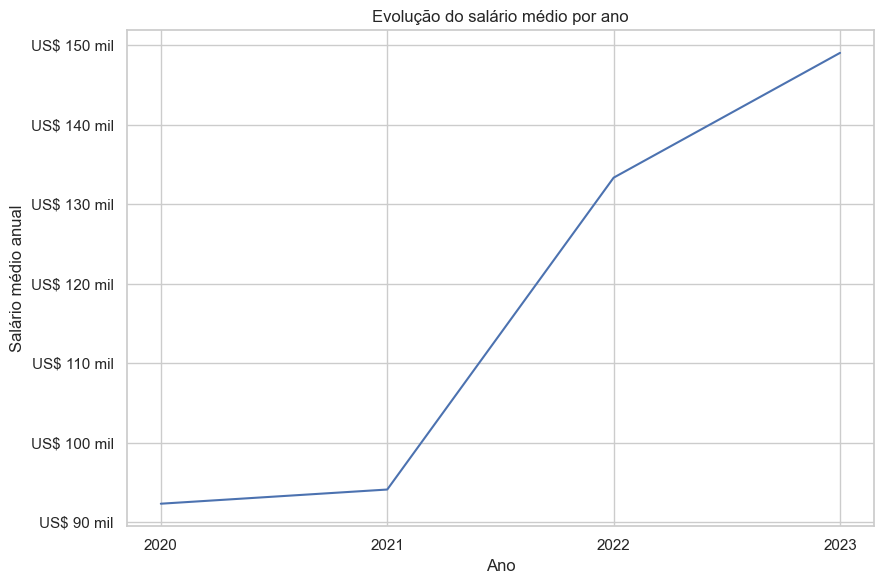

In [67]:
plt.figure(figsize=(9, 6))

sns.lineplot(data=salary_by_years, x="work_year", y="Media", markers="o")

plt.title(f"Evolução do salário médio por ano")
plt.xlabel(f"Ano")
plt.ylabel(f"Salário médio anual")
plt.xticks(salary_by_years["work_year"])

ax = plt.gca()

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"US$ {y / 1_000:.0f} mil"))

plt.tight_layout()
plt.show()

### 11.4 Variação percentual da mediana salarial

Para quantificar a evolução entre os anos, será calculada a variação percentual da mediana em relação ao ano anterior.

In [68]:
median_by_year = salary_by_years.set_index("work_year")["Mediana"]

median_annual_variation = median_by_year.pct_change() * 100

annual_comparison = pd.DataFrame(
    {"Mediana": median_by_year, "Variacao_Percentual": median_annual_variation}
)

annual_comparison

,Mediana,Variacao_Percentual
work_year,,
2020,73065.0,NaN
2021,80000.0,9.491549
2022,131300.0,64.125000
2023,143860.0,9.565880


In [69]:
annual_comparison_display = annual_comparison.copy()

annual_comparison_display["Mediana"] = annual_comparison_display["Mediana"].map(
    lambda x: f"US$ {x:,.2f}"
)

annual_comparison_display["Variacao_Percentual"] = annual_comparison_display[
    "Variacao_Percentual"
].map(lambda x: "-" if pd.isna(x) else f"{x:.2f}%")

annual_comparison_display

,Mediana,Variacao_Percentual
work_year,,
2020,"US$ 73,065.00",-
2021,"US$ 80,000.00",9.49%
2022,"US$ 131,300.00",64.13%
2023,"US$ 143,860.00",9.57%


### 11.5 Distribuição salarial por ano

O boxplot permite observar como a distribuição dos salários mudou entre os anos, incluindo mediana, dispersão e valores extremos.

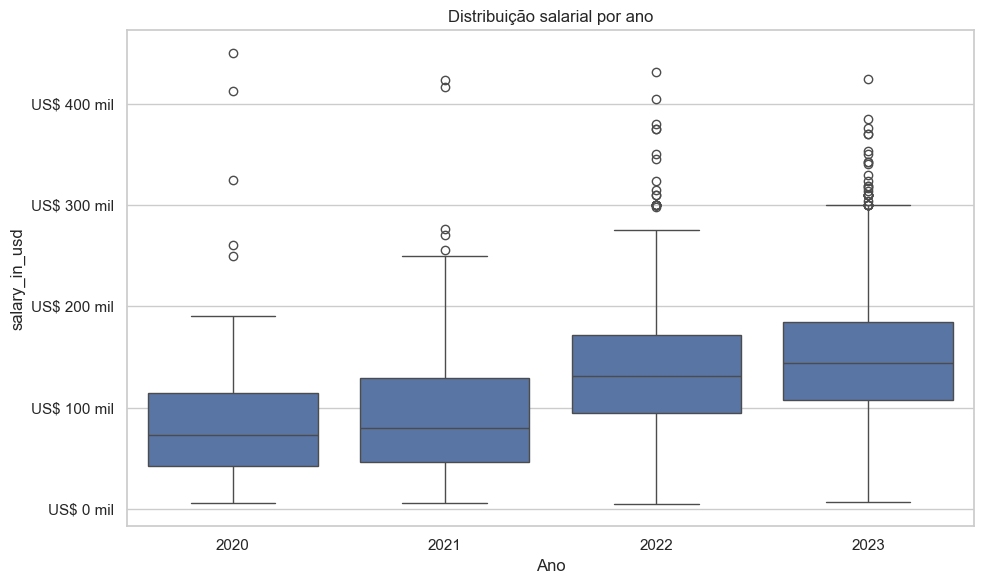

In [70]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="work_year", y="salary_in_usd")

plt.title(f"Distribuição salarial por ano")
plt.xlabel(f"Ano")
plt.ylabel(f"salary_in_usd")

ax = plt.gca()

ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"US$ {y / 1_000:.0f} mil"))

plt.tight_layout()
plt.show()

### 11.6 Interpretação da evolução salarial ao longo dos anos

Os resultados mostram crescimento relevante dos salários ao longo do período analisado.

A mediana salarial passou de aproximadamente **US$ 73,1 mil em 2020** para **US$ 80 mil em 2021**, representando aumento de aproximadamente **9,49%**.

Entre 2021 e 2022 ocorreu a maior variação observada no período: a mediana aumentou para aproximadamente **US$ 131,3 mil**, uma elevação de cerca de **64,13%**.

Em 2023, a mediana atingiu aproximadamente **US$ 143,9 mil**, crescimento adicional de aproximadamente **9,57%** em relação a 2022.

A média salarial apresentou comportamento semelhante, aumentando de aproximadamente **US$ 92,3 mil em 2020** para **US$ 149 mil em 2023**.

Os boxplots também evidenciam um deslocamento da distribuição salarial para valores mais elevados principalmente a partir de 2022.

Entretanto, a evolução deve ser interpretada com cautela. A quantidade de observações varia significativamente entre os anos:

- 2020: 76 registros;
- 2021: 230 registros;
- 2022: 1.664 registros;
- 2023: 1.785 registros.

Consequentemente, mudanças na composição da amostra — como proporção de profissionais seniores, países representados, cargos e portes de empresa — também podem contribuir para as diferenças observadas.

Dessa forma, os resultados mostram uma forte associação entre anos mais recentes e maiores salários na base analisada, mas não permitem atribuir essa diferença exclusivamente a uma valorização temporal dos salários.

# 12. Correlação entre variáveis numéricas

Nesta etapa será analisada a correlação linear entre as variáveis numéricas disponíveis na base.

A análise considera:

- `salary_in_usd`;
- `years_of_experience`;
- `work_year`.

A correlação de Pearson varia entre -1 e 1 e ajuda a identificar a direção e a intensidade da associação linear entre duas variáveis.

É importante destacar que correlação não implica causalidade.

### 12.1 Matriz de correlação

A matriz de correlação será utilizada para resumir as relações lineares entre as variáveis numéricas.

In [71]:
numerical_variables = ["work_year", "years_of_experience", "salary_in_usd"]

correlation_matrix = df[numerical_variables].corr()

correlation_matrix.round(4)

,work_year,years_of_experience,salary_in_usd
work_year,1.0000,0.1789,0.2283
years_of_experience,0.1789,1.0000,0.4107
salary_in_usd,0.2283,0.4107,1.0000


### 12.2 Visualização da matriz de correlação

O heatmap facilita a interpretação visual da intensidade e da direção das correlações observadas.

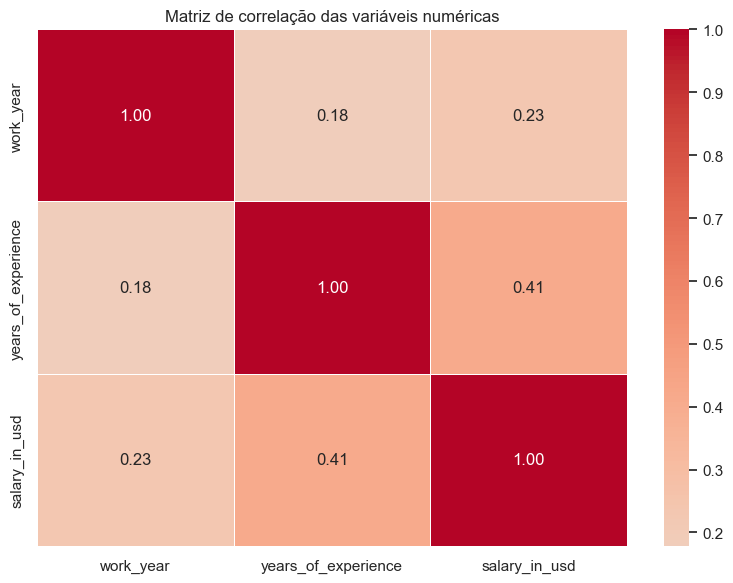

In [72]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5
)

plt.title(f"Matriz de correlação das variáveis numéricas")

plt.tight_layout()

plt.savefig("../images/matriz_correlação.png", dpi=300, bbox_inches="tight")

plt.show()

### 12.3 Correlações com `salary_in_usd`

Para facilitar a interpretação, serão destacadas apenas as correlações das demais variáveis numéricas com o salário.

In [73]:
salary_correlations = (
    correlation_matrix["salary_in_usd"]
    .drop("salary_in_usd")
    .sort_values(ascending=False)
)

salary_correlations

years_of_experience    0.410723
work_year              0.228290
Name: salary_in_usd, dtype: float64

### 12.4 Interpretação das correlações

A matriz de correlação mostra que as variáveis numéricas apresentam associações positivas com `salary_in_usd`, embora com intensidades diferentes.

A maior correlação observada com o salário foi de `years_of_experience`, com valor de aproximadamente **0,4107**.

Esse resultado indica uma **associação linear positiva moderada** entre experiência profissional e remuneração, reforçando a tendência observada anteriormente nos gráficos e nas medianas salariais por anos de experiência.

A variável `work_year` apresentou correlação de aproximadamente **0,2283** com `salary_in_usd`, indicando uma associação positiva mais fraca.

Isso é compatível com a análise temporal, na qual os salários se mostraram maiores nos anos mais recentes, principalmente em 2022 e 2023.

Entretanto, `work_year` deve ser interpretado com cautela. Apesar de ser representado numericamente, ele funciona principalmente como uma variável temporal e a composição da amostra muda significativamente entre os anos.

Também foi observada correlação de aproximadamente **0,1789** entre `work_year` e `years_of_experience`, indicando uma associação positiva fraca entre essas duas variáveis.

De forma geral, nenhuma das correlações observadas é suficientemente alta para indicar que uma única variável numérica explica isoladamente as diferenças salariais.

Os resultados reforçam a ideia de que a remuneração parece estar relacionada a múltiplos fatores, incluindo experiência, cargo, localização, porte da empresa e período do registro.

# 13. Principais insights da análise

A análise estatística dos salários de profissionais de dados revelou padrões relevantes relacionados à experiência, cargo, localização, porte da empresa e período do registro.

Os principais insights encontrados foram:

### 1. A experiência profissional está associada a salários mais altos

A mediana salarial cresce de forma consistente conforme aumenta o nível de experiência:

- Entry-level (`EN`): aproximadamente **US$ 70 mil**;
- Mid-level (`MI`): aproximadamente **US$ 100 mil**;
- Senior (`SE`): aproximadamente **US$ 146 mil**;
- Executive (`EX`): aproximadamente **US$ 196 mil**.

A correlação entre anos de experiência e salário foi de aproximadamente **0,4107**, indicando uma associação positiva moderada.

---

### 2. Cargos especializados apresentam remunerações mais elevadas

Entre os cargos com pelo menos 30 registros, as maiores medianas foram observadas em funções como:

- `Applied Scientist`: aproximadamente **US$ 191,7 mil**;
- `Data Science Manager`: aproximadamente **US$ 183,8 mil**;
- `Data Architect`: aproximadamente **US$ 160 mil**;
- `ML Engineer`: aproximadamente **US$ 160 mil**;
- `Research Engineer`: aproximadamente **US$ 155 mil**.

Esses resultados sugerem que funções de maior especialização técnica, pesquisa e gestão tendem a apresentar remunerações superiores dentro da base analisada.

---

### 3. A localização apresenta forte associação com a remuneração

Os Estados Unidos apresentaram a maior mediana salarial entre os países com pelo menos 30 registros, com aproximadamente **US$ 145 mil**.

Na sequência aparecem:

- Canadá: aproximadamente **US$ 120 mil**;
- Reino Unido: aproximadamente **US$ 80 mil**;
- Alemanha: aproximadamente **US$ 76,8 mil**.

Essas diferenças mostram que a localização geográfica está fortemente associada aos níveis salariais observados.

---

### 4. Empresas médias apresentaram as maiores medianas salariais

A mediana salarial por porte de empresa foi aproximadamente:

- pequena (`S`): **US$ 62,1 mil**;
- média (`M`): **US$ 140 mil**;
- grande (`L`): **US$ 108,5 mil**.

O resultado mostra que a relação entre porte da empresa e salário não é linear, já que empresas médias apresentaram remuneração central superior às empresas grandes.

---

### 5. Os salários aumentaram nos anos mais recentes da base

A mediana salarial evoluiu de aproximadamente:

- **US$ 73,1 mil em 2020**;
- **US$ 80 mil em 2021**;
- **US$ 131,3 mil em 2022**;
- **US$ 143,9 mil em 2023**.

O maior crescimento ocorreu entre 2021 e 2022.

Entretanto, a composição da amostra muda significativamente entre os anos, portanto essa evolução não deve ser interpretada isoladamente como crescimento real do mercado.

---

### 6. A distribuição salarial apresenta elevada heterogeneidade

O salário médio da base foi de aproximadamente **US$ 137,6 mil**, enquanto a mediana ficou próxima de **US$ 135 mil**.

O coeficiente de variação foi de aproximadamente **45,84%**, evidenciando alta dispersão salarial.

A distribuição apresentou assimetria positiva de aproximadamente **0,5364**, indicando a presença de uma cauda à direita associada a remunerações mais elevadas.

---

### 7. Os valores extremos parecem representar casos plausíveis

Pelo método do intervalo interquartil, foram identificados **63 possíveis outliers**, correspondentes a aproximadamente **1,68% da base**.

A maior parte desses registros pertence a profissionais Senior ou Executive, cargos especializados e profissionais dos Estados Unidos.

Como esses valores apresentam características plausíveis dentro do contexto analisado, os outliers foram mantidos na análise.

---

### 8. Nenhuma variável isolada explica completamente o salário

Embora experiência, localização, cargo, porte da empresa e ano estejam associados à remuneração, os resultados indicam que nenhuma variável, isoladamente, explica todas as diferenças salariais.

Isso reforça a natureza multifatorial da remuneração no mercado de profissionais de dados.

# 14. Conclusão do projeto

Este projeto teve como objetivo analisar estatisticamente os salários de profissionais da área de dados, buscando identificar padrões associados à experiência, cargo, localização, porte da empresa e período do registro.

A análise utilizou uma base com **3.755 registros** e **10 variáveis**, permitindo explorar diferentes dimensões da remuneração no mercado de dados.

### 14.1 Conclusões principais

Os resultados mostram que a remuneração dos profissionais de dados está associada a múltiplos fatores.

A experiência profissional apresentou relação positiva com os salários. Profissionais em níveis mais elevados de senioridade apresentaram medianas significativamente superiores às observadas entre profissionais iniciantes.

Também foram identificadas diferenças importantes entre cargos. Funções relacionadas a maior especialização técnica, pesquisa, arquitetura e gestão apresentaram remunerações superiores entre os cargos com amostra suficiente para comparação.

A localização geográfica mostrou forte associação com os salários. Entre os países com pelo menos 30 registros, os Estados Unidos apresentaram a maior mediana salarial.

O porte da empresa também apresentou diferenças relevantes, embora sem uma relação linear: empresas médias apresentaram maior mediana salarial do que empresas grandes e pequenas.

A análise temporal mostrou aumento dos salários nos anos mais recentes da base, principalmente entre 2021 e 2022. Entretanto, essa evolução deve ser interpretada considerando as mudanças na composição da amostra ao longo do período.

De forma geral, os resultados indicam que o salário no mercado de dados possui natureza multifatorial e não pode ser explicado adequadamente por uma única característica.

### 14.2 Limitações do projeto

Algumas limitações devem ser consideradas na interpretação dos resultados:

- a base apresenta forte concentração de registros nos Estados Unidos e na região das Américas;
- profissionais Senior representam a maior parte da amostra;
- empresas médias também concentram grande parte dos registros;
- os anos de 2022 e 2023 possuem muito mais observações do que 2020 e 2021;
- algumas regiões e países possuem amostras muito pequenas;
- a base não possui um identificador único por profissional, impossibilitando confirmar se registros completamente iguais representam duplicatas reais ou indivíduos distintos;
- as análises realizadas são predominantemente descritivas e associativas;
- correlação e diferenças entre grupos não implicam causalidade;
- fatores como formação acadêmica, setor da empresa, benefícios, custo de vida e tipo de contrato não estão disponíveis na base.

Essas limitações devem ser consideradas antes de generalizar os resultados para todo o mercado de profissionais de dados.

### 14.3 Possíveis próximos passos

Como evolução futura, este projeto pode incluir:

- testes estatísticos para comparação entre grupos;
- análise de significância das diferenças salariais;
- modelos de regressão para estimar o efeito conjunto das variáveis;
- normalização dos salários por custo de vida;
- análise específica por país;
- estudo da interação entre cargo e experiência;
- criação de dashboards interativos;
- comparação com bases salariais de outros períodos;
- construção de modelos preditivos de salário.

### 14.4 Encerramento

O projeto demonstrou como técnicas de estatística descritiva e análise exploratória podem ser utilizadas para transformar uma base salarial em informações relevantes sobre o mercado de profissionais de dados.

A análise evidenciou diferenças importantes relacionadas à senioridade, experiência, função profissional, localização, porte da empresa e período analisado.

Além dos resultados quantitativos, o projeto reforça a importância de considerar tamanho da amostra, valores extremos, distribuição dos dados e limitações metodológicas antes de interpretar diferenças salariais.

Como resultado final, foi construída uma visão estruturada e estatisticamente fundamentada dos principais fatores associados à remuneração dos profissionais de dados presentes no conjunto analisado.

# 15. Exportação das visualizações

As principais visualizações do projeto serão exportadas para a pasta `images/` para utilização na documentação do repositório.

A seleção prioriza gráficos que resumem os principais padrões identificados na análise.